In [1]:
import numpy as np
import pandas as pd
import chec_seq_analysis_tools as csat
import matplotlib.pyplot as plt
from time import time
from itertools import product, chain
from scipy.fft import next_fast_len, rfft, irfft
from numba import njit, prange

In [2]:
#%matplotlib ipympl

# Calculating A-DNA Dinucleotide Content

In [3]:
def standardize_promoter_coordinates(promoter_info_list):
    """
    Function that takes a list whose elements are lists with the chromosme, promoter start coordinate, and promoter end
    coordinate and converts the coordinate into left and right. This is done to ensure that when determining which promoters
    are shared between constructs, the coordinates are not sensitive to direction; this mainly accounts for two promoters that
    occur with the same left and right coordinates but on opposites strands (the start and end coordinates would be flipped).
    Don't know if that actually happens a lot, but might as well be thorough.

    Parameters
    ----------
    promoter_info_list : list
        List whose elements are lists containing the chromosome, promoter start coordinate, and promoter end coordinate for
        each promoter (each element has the information for a different promoter)

    Returns
    -------
    standardized_info_list : tuple
        List where the start and end coordinates have been converted to left and right coordinates.
    """
    # create an empty list to stored the converted promoter information
    standardized_info_list = []
    # iterate over each set of promoter information in the input list
    for promoter in promoter_info_list:
        # initialize variables for the chromosome, start coordinate, and end coordinate
        chrom, start, end = promoter
        # determine the left and right coordinates based on value; smaller = left, larger = right
        lc = min(start, end)
        rc = max(start, end)
        # add chromsome, left coordinate, and right coordinate to emtpy list from earlier as a list
        standardized_info_list.append((chrom, lc, rc))
    return standardized_info_list

def dinucleotide_counter(seq, dinucleotide):
    """
    Function that counts the number of times a particular dinculetodies appears in the input sequence. This is done by converting the DNA 
    basepair sequences to numbers (A = 0, C = 1, G = 2, T = 3), breaking the sequence into each possible dinucleotide, then counting how
    many dinucleotides are different, then subtracting that from the total number of dinucleotides (faster then counting the number of 
    dinucleotides that are the same).

    Parameters
    ----------
    seq : string
        String containing the DNA sequence of interest. This string should only contain A,C,G, and/or T and they should all be capitalized.
        There should be no spaces between the letters.
    dinucleotide : string
        String containing the dinucleotide to count in the seuqence of interest (seq). This string should contain only 2 base pairs that are
        input as A,C,G, and/or T that are also capitalized. There should be no spaces between the letters.

    Return
    ------
    num_same_seq_dinucleotides : float
        Number of times the input dinucleotide appears in the DNA sequence of interest.
    """
    # define a translation table that converts the bases to numbers via hexa decimal
    trans_table = str.maketrans('ACGT', '\x00\x01\x02\x03')
    # convert the sequence and dinucleotide into arrays where each base has been replaced by a number
    seq_converted = np.frombuffer(seq.translate(trans_table).encode(), dtype=np.uint8)
    # make sure the converted dinculeotide is a row array/vector for later
    dinucleotide_converted = np.frombuffer(dinucleotide.translate(trans_table).encode(), dtype=np.uint8).reshape(1,-1)
    # break the sequence into its possible dinucleotides by sliding a window of length 2 along the entire sequence
    # this results in a 2D array where each row reprsents a dinucleotide
    seq_converted_dinculeotides = np.lib.stride_tricks.sliding_window_view(seq_converted, 2,0)
    # obtain the number of dinucleotides from the previous 2D array
    num_total_seq_dinucleotides = seq_converted_dinculeotides.shape[0]
    # subtract the converted dincleotide array from each converted dinucleotide array in the seque     
    base_diff = seq_converted_dinculeotides - dinucleotide_converted
    # take the absolute value of the previous array then sum each row; if the sum of a row is 0, it matches the dinucleotide.
    abs_base_diff = np.abs(base_diff)
    dinucleotide_diff = np.sum(abs_base_diff, axis = 1, keepdims = True)
    # count the number of rows with a nonzero sum; this represents the number of dinucleotides in the sequence that do not match
    num_diff_seq_dinucleotides = np.count_nonzero(dinucleotide_diff)
    # subtract the number of different dinucleotides in the sequence from the total number of dinucleotides in sequence 
    # this difference is the number of dinucleotides in the sequence that are the same as the input dinucleotide
    num_same_seq_dinucleotides = num_total_seq_dinucleotides - num_diff_seq_dinucleotides
    return num_same_seq_dinucleotides

In [4]:
# to access genome more easily, store inside dictionary
# with chromosomes as the key and the chromosome sequences as the values
genome_file = "S288C_reference_genome_R64-1-1_20110203/S288C_reference_sequence_R64-1-1_20110203.fsa"
gff_file_path = "S288C_reference_genome_R64-1-1_20110203/saccharomyces_cerevisiae_R64-1-1_20110208.gff"
# read genome file
genome_dict = csat.genome_dictionary_generator(genome_file)

In [5]:
f = []
r = []
for i in genome_dict.keys():
    seq = genome_dict[i]
    f.append(seq.count('AGGGG'))
    r.append(seq.count('CCCCT'))
f_sum = sum(f)
r_sum = sum(r)
print(f_sum,r_sum,f_sum+r_sum)

4207 4243 8450


In [6]:
f

[82, 287, 107, 546, 204, 98, 369, 196, 186, 250, 223, 355, 309, 270, 377, 348]

In [7]:
# identify the promoters unique to each construct as well as those in all of them
full_promoters = standardize_promoter_coordinates(pd.read_csv('Msn2_Full_60sec_Target_Promoters_Info.csv').iloc[:,1:4].values.tolist())
dbd_promoters = standardize_promoter_coordinates(pd.read_csv('Msn2_DBD_60sec_Target_Promoters_Info.csv').iloc[:,1:4].values.tolist())
idr_promoters = standardize_promoter_coordinates(pd.read_csv('Msn2_non_DBD_60sec_Target_Promoters_Info.csv').iloc[:,1:4].values.tolist())

full_promoters_tup = list(map(tuple, full_promoters))
dbd_promoters_tup = list(map(tuple, dbd_promoters))
idr_promoters_tup = list(map(tuple, idr_promoters))

master_promoters_list = list(chain(full_promoters, dbd_promoters, idr_promoters))
standardized_master_promoters_list = standardize_promoter_coordinates(master_promoters_list)
all_unique_promoters_list = list(set(standardized_master_promoters_list))
unique_promoters_dict = {}

for promoter in all_unique_promoters_list:
    if (promoter in full_promoters_tup) and (promoter in dbd_promoters_tup) and (promoter in idr_promoters_tup):
        if 'Shared' not in unique_promoters_dict.keys():
            unique_promoters_dict['Shared'] = [promoter]
        else:
            unique_promoters_dict['Shared'].append(promoter)
    elif (promoter in full_promoters_tup) and (promoter in dbd_promoters_tup):
        if 'Full_DBD' not in unique_promoters_dict.keys():
            unique_promoters_dict['Full_DBD'] = [promoter]
        else:
            unique_promoters_dict['Full_DBD'].append(promoter)
    elif (promoter in full_promoters_tup) and (promoter in idr_promoters_tup):
        if 'Full_non_DBD' not in unique_promoters_dict.keys():
            unique_promoters_dict['Full_non_DBD'] = [promoter]
        else:
            unique_promoters_dict['Full_non_DBD'].append(promoter)
    elif (promoter in dbd_promoters_tup) and (promoter in idr_promoters_tup):
        if 'Full_DBD' not in unique_promoters_dict.keys():
            unique_promoters_dict['DBD_non_DBD'] = [promoter]
        else:
            unique_promoters_dict['DBD_non_DBD'].append(promoter)
    elif (promoter in full_promoters_tup):
        if 'Full_only' not in unique_promoters_dict.keys():
            unique_promoters_dict['Full_only'] = [promoter]
        else:
            unique_promoters_dict['Full_only'].append(promoter)
    elif (promoter in dbd_promoters_tup):
        if 'DBD_only' not in unique_promoters_dict.keys():
            unique_promoters_dict['DBD_only'] = [promoter]
        else:
            unique_promoters_dict['DBD_only'].append(promoter)
    elif (promoter in idr_promoters_tup):
        if 'non_DBD_only' not in unique_promoters_dict.keys():
            unique_promoters_dict['non_DBD_only'] = [promoter]
        else:
            unique_promoters_dict['non_DBD_only'].append(promoter)

In [8]:
mot = 'AGGGG'
dinuc = 'GG'
x = dinucleotide_counter(mot, dinuc)
y = mot.count(dinuc)
print(x,y)

3 2


In [9]:
# creat empty dictionary to store densities/relative content
# that relate construct/group to its metrics
a_dna_fraction_dict = {}
a_dna_density_dict = {}
# make a list of all constucts/groups to look at and iterate over them
all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
for construct in all_constructs:
    # initialize empty lists to store the metrics for a particular group/construct
    fraction_list = []
    density_list = []
    # keep a running total of the number of A-DNA dinucleotides and total dinucleotides
    # for each construct/group
    a_dna_dinuc_count = 0
    total_2mer_count = 0
    # for target promoters, need to use the genome dictionary to access the sequences
    if construct in ['Full', 'DBD', 'non_DBD']:
        word = 'promoters'
        # grab the file with the target promoter locatoin info
        target_promoters_file = f'Msn2_{construct}_60sec_Target_Promoters_Info.csv'
        # convert .csv file into a Pandas DataFrame
        target_promoters_df = pd.read_csv(target_promoters_file)
        # convert DataFrame into list where each row of the DF is a list element
        target_promoters_location = target_promoters_df.loc[:, ['chr', 'Promoter Start Site', 'Promoter End Site']].values.tolist()
        for promoter in target_promoters_location:
            # grab promtoer start, end, and chromosome
            chrom, start, end = promoter
            # convert start and end to left and right coordinates for sequence extraction
            lc = min(start, end)
            rc = max(start, end)
            # extract promoter sequence
            seq = genome_dict[chrom][lc:rc+1]
            # calculate number of dinucleotides in the sequence
            dinucs_in_seq = len(seq)-1
            # add number of total dinucleotides to running total
            total_2mer_count += dinucs_in_seq
            # calculte number of A-DNA dinucleotides in sequence
            CC_count = dinucleotide_counter(seq, 'CC')
            GG_count = dinucleotide_counter(seq, 'GG')
            CG_count = dinucleotide_counter(seq, 'CG')
            GC_count = dinucleotide_counter(seq, 'GC')
            a_dna_dinuc_in_seq = CC_count + GG_count + CG_count + GC_count
            # add number of A-DNA dinucleotides to running total
            a_dna_dinuc_count += a_dna_dinuc_in_seq
            # calculate realtive A-DNA dinucleotide content
            a_dna_fraction = a_dna_dinuc_in_seq/dinucs_in_seq
            # calculate A-DNA density
            a_dna_density = a_dna_dinuc_in_seq/(rc-lc+1)
            fraction_list.append(a_dna_fraction)
            # append metrics to the empty lists from earlier
            density_list.append(a_dna_density)
    else:
        # for all other contructs/groups, don't need genome to get sequences
        if construct == 'All':
            info_file = 'Msn2_60sec_Unique_Promoters_Info.csv'
            word = 'promoter'
        elif construct == 'Intergenic':
            info_file = 'Msn2_60sec_Intergenic_Regions_Info.csv'
            word = 'regions'
        else:
            info_file = f'Msn2_{construct[:-3]}_60sec_nonspecific_sequences.csv'
            word = 'sequences'
        # convert .csv file with sequences into a Pandas DataFrame
        info_df = pd.read_csv(info_file)
        # extract a list of the sequences from the DF
        info_seqs = info_df.loc[:, ['Sequence']].values.flatten().tolist()
        for seq in info_seqs:
            # calculate number of dinucleotides for the sequence
            dinucs_in_seq = len(seq)-1
            # add number to running total of total dinucleotides
            total_2mer_count += dinucs_in_seq
            # calculate number of A-DNA dinucleotides
            CC_count = dinucleotide_counter(seq, 'CC')
            GG_count = dinucleotide_counter(seq, 'GG')
            CG_count = dinucleotide_counter(seq, 'CG')
            GC_count = dinucleotide_counter(seq, 'GC')
            a_dna_dinuc_in_seq = CC_count + GG_count + CG_count + GC_count
            # add number to running total of total A-DNA dinucleotides
            a_dna_dinuc_count += a_dna_dinuc_in_seq
            # calculate relative A-DNA dinucleotide content
            a_dna_fraction = a_dna_dinuc_in_seq/dinucs_in_seq
            # calculate A-DNA Density
            a_dna_density = a_dna_dinuc_in_seq/(len(seq))
            # append metrics to empty list from earlier
            fraction_list.append(a_dna_fraction)
            density_list.append(a_dna_density)
    # for each construct, append lists of metrics to empty dictionaries from earlier
    a_dna_fraction_dict[construct] = np.array(fraction_list)
    a_dna_density_dict[construct] = np.array(density_list)
    # print total number of A-DNA dinucleotides and percent of A-DNA dinucleotides
    # per construct/group
    print(f'For {construct} {word}, there are {a_dna_dinuc_count} CC, GG, GC, and CG dinucleotides combined out of {total_2mer_count} total dinculeotides.')
    print(f'This represents {(a_dna_dinuc_count/total_2mer_count)*100} percent of all 2mers in these {word} \n')

For Full promoters, there are 13482 CC, GG, GC, and CG dinucleotides combined out of 72183 total dinculeotides.
This represents 18.677527949794275 percent of all 2mers in these promoters 

For DBD promoters, there are 9424 CC, GG, GC, and CG dinucleotides combined out of 60246 total dinculeotides.
This represents 15.642532284301033 percent of all 2mers in these promoters 

For non_DBD promoters, there are 16800 CC, GG, GC, and CG dinucleotides combined out of 90526 total dinculeotides.
This represents 18.558204272805604 percent of all 2mers in these promoters 

For All promoter, there are 313129 CC, GG, GC, and CG dinucleotides combined out of 2293368 total dinculeotides.
This represents 13.65367442120061 percent of all 2mers in these promoter 

For Intergenic regions, there are 442024 CC, GG, GC, and CG dinucleotides combined out of 3446330 total dinculeotides.
This represents 12.825933674372447 percent of all 2mers in these regions 

For Full_NS sequences, there are 1699467 CC, GG, G

# Construct A-DNA Dinucleotide Densities

In [10]:
def Scotts_rule_width(data):
    '''
    Function that uses Scott's Rule of Thumb to calculate the bandwith for a kernel density estimation. It factors in the standard
    deviation of the data as well as the number of points. It also factors in dimensionality but because my data is 1D, I just have 
    d = 1 and not bother with it. Function assumes that if the data is passed as a 2D or 3D array, then then each column is a set of data
    to calculate bandwidths for which means that it assumes each column has data obtained with a different set of parameters.

    Parameters
    ----------

    data : ndarray
        Array containing the data whose pdf will be estimated via kernel density estimation (KDE) approach. It can be 1D, 2D, or 3D.

    Return
    ------

    widths : ndarray
        Array containing the bandwidth(s). Returned array will always be 2D since the axis parameter is always defined when possible. For 
        2D or 3D arrays, there will be as many bandwidths as there are columns.
    '''
    # determine the array index number for rows of the data array; 0 if 1D or 2D, 1 if 3D
    row_idx = np.clip(data.ndim - 2, 0, None)
    # grab the number of data points (or number of data points per column if a 2D or 3D array)
    ndata = data.shape[row_idx]
    # calculate mean(s) of data
    mean = np.mean(data, axis = row_idx, keepdims = True)
    # calculate the mean(s) of the data**2
    mean_2 = np.mean(data**2, axis = row_idx, keepdims = True)
    # calculate variance
    var = mean_2 - mean**2
    # calculate standard deviation(s)
    std = np.sqrt(var)
    # use number of data points and standard deviation(s) to calculate bandwidth(s)
    widths =  std*(ndata**(-0.2))
    return widths
    
def col_trap_int(array, bins):
    '''
    Function that integrates an array. The array should be output values corresponding to the values in bins (the values in bins, when put
    into whatever function or pdf should lead to the values in the array). Additionally, the array should be such that each column is its
    own set and the integration will be performed over each column. This is to be used in the gkde() function to renormalize the pdfs. To 
    calculate the integral using numpy, the trapezoid approximation is used.

    Parameters
    ----------

    array : ndarray
        A 1D, 2D, or 3D numpy array representing the "y" values or function values.
    bins : 1D array
        "x" values ues to obtain the "y" values represented by the array input parameter. They don't necessarily have to be evenly spaced,
        but it is common practice for them to be.

    Return
    ------

    areas : ndarray
        Array containing the approximated integral of each column. The output array perserves the number of arrays (if 3D) and number of 
        columns (if 2D or 3D) but reduces the number of rows to 1. For a 1D array, the output array has shape (1,1).
    '''
    # determine the height of each trapezoid from the bins
    dx = bins[1:] - bins[:-1]
    # find the dimensionality of the input array; this determines how the integral is calculated and the shape of the output
    array_dim = array.ndim
    # if the array is 3D, calculate the integral of each column of each array
    if array_dim == 3:
        bases_1 = array[:, :-1, :]
        bases_2 = array[:, 1:, :]
        dx = dx.reshape(-1,1)
        trapezoids = (bases_1 + bases_2)*dx*0.5
        areas = np.sum(trapezoids, axis = 1, keepdims = True)
    # if the array is 2D, calculate the integral of each column
    elif array_dim == 2:
        bases_1 = array[:-1, :]
        bases_2 = array[1:, :]
        dx = dx.reshape(-1,1)
        trapezoids = (bases_1 + bases_2)*0.5*dx
        areas = np.sum(trapezoids, axis = 0, keepdims = True)
    # if the array is 1D, calculate the integral of the array
    elif array_dim == 1:
        bases_1 = array[:-1]
        bases_2 = array[1:]
        trapezoids = (bases_1 + bases_2)*0.5*dx
        area = np.sum(trapezoids)
    return areas

   
def linear_bins(data, bins):
    '''
    Function that takes a set of bins and a set of data and determines the linear bin values for each bin. Linear bin values means that 
    rather than placing the entire weight (1) of each data point into a bin, the weight of each point is linearly divdied into the bins on 
    both sides of the data point depending on the distance to the bin.  Bins that are closer to the actual data point have more weight and 
    vice versa. This is to be used for KDE calculations later. For 2D and 3D arrays, function linear bins each column. This to be used in 
    order to obtain an KDE estimated pdf of the data in another function.

    Parameters
    ----------
    data : ndarray
        A 1D, 2D, or 3D numpy array containing the data to be linear binned.

    bins : 1D array
        1D numpy array containing the grid along which to linearly bin the data. The points in the array need to be evenly spaced.

    Returns
    -------
    linear_bin_vals : 3D array
        3D array containing the linearly binned data. The actual values represents the weight of each data point distributed linearly 
        across the grid defined by the bins input parameter. The output array preserves the number of arrays (if input array is 3D) and the
        number of columns (if input array is 2D or 3D), but the number of rows is equal to the number of bin edges (length of input bins 
        parameter). If the input array is 2D or 1D, the number of arrays is 1; if the input array is 1D, the number of columns is also 1.
    '''
    # get number of bins and data_array dimensions
    ndim  = data.ndim
    if ndim == 3:
        narr, nrow, ncol = data.shape
    elif ndim == 2:
        nrow, ncol = data.shape
        narr = 1
    else:
        nrow = data.shape[0]
        narr, ncol = 1,1
    num_bins = bins.shape[0]+1
    step = bins[1] - bins[0]
    # use search sorted and clip to find the lower bin indicies each data point has
    data_bin_values = ((data - bins[0])/step).ravel()
    data_bin_indices = np.floor(data_bin_values).astype(int).ravel()
    # create indices for the array and columns for later
    array_indices = np.repeat(np.arange(narr),nrow*ncol)
    column_indices = np.tile(np.arange(ncol), narr*nrow)
    # calculate the values for each upper bin; this is data - lower bin value. This ensures that upper bins closer to the data point
    # have more weight
    upper_bin_values = data_bin_values - data_bin_indices
    # calculate the values for each lower bin; this is 1 - upper_bin_values. This ensures that data points closer to the lower bin have
    # more weight
    lower_bin_values = 1 - upper_bin_values
    # calculate offsets to add to bin indices to use for np.bincount
    offsets = (array_indices*ncol + column_indices)*num_bins
    # adjust lower bin and upper bin indices by the offsets
    lower_flat_counts = data_bin_indices + offsets
    upper_flat_counts = (data_bin_indices +  1) + offsets
    # get the lower bin values in the correct shape
    lower_hist = np.bincount(lower_flat_counts, weights = lower_bin_values, minlength = num_bins*(narr*ncol)).reshape(narr, ncol, num_bins).transpose(0,2,1)
    # get the upper bin values the correct shape
    upper_hist = np.bincount(upper_flat_counts, weights = upper_bin_values, minlength = num_bins*(narr*ncol)).reshape(narr, ncol, num_bins).transpose(0,2,1)
    # add the upper and lower bin value arrays to get the full linear binning
    linear_bin_vals = lower_hist + upper_hist
    return linear_bin_vals

def gkde(data, bins, bw, smoothing_factor = 1e-12):
    '''
    Function that estimates the probability density functions (pdf) of each column of the data over the points in bins. This is done using 
    a Kernel Density Estimator (KDE) approach where a gaussian is applied to each data point in each column to build the pdf. To do this
    quickly requires linearly binning the data, applying Fourier Transforms on the linear bins and gaussians around each data point,
    multilpying the results Fourier Transforms, then applying an inverse Fourier Transform on the product. The resulting inverse transform
    is the normalized to yield the raw pdfs. To ensure that end result is properly normalized as well as that for Kullback-Leibler and
    log-odds calculations downstream, a smoothing factor is added to each value to prevent diving or taking the log of 0 then renormalized.
    This essentially transforms any zeros in the raw pdfs to the value of the smoothing factor. Additionally, the renormalization ensures
    that not only is the pdf properly normalized after the smoothing factor, but if any density leaked due to the hard boundary at 0, this
    is accounted for. This function relies on the fact that the KDE is essentially a convolution of the kernel and a dirac delta function
    and convolutions in the frequency domain (AKA after a fourier transform of each function) is just a product. The linear binning
    procedure is a way to approximate the dirac delta and the kernel used for the KDE is a gaussian kernel.

    Parameters
    ----------
    data : ndarray
        A 1D, 2D or 3D numpy array containing columns of data whose pdfs are to be estimated.
    bins : 1D array
        1D numpy array containing the 1D grid to linearly bin the data; it is essentially the points to calculate the pdf for. The points
        in the array must be evenly spaced.
    bw : float or 1D array
        float or 1D array containing the bandwidths to use for the KDE. If the data is a 1D array of 2D array with 1 column, the bandwidth
        should be a float, 1D array with shape (1,) or 2D array with shape (1,1). If the data is a 2D array with multiple columns or 3D
        array, bw should have the same number of arrays (if 3D) and the same number of columns but 1 row.
    smoothing factor : float (default : 1e-12)
        Value to add to the raw pdfs. If the Kullback-Leibler divergence or Log-Odds is calculated down the road, this ensures that there 
        are no zeros in the pdf so it should results in an error due to dividing by 0 and taking the logarithm of 0. Default value is 
        1e-12. The smallest nonzero data point is on the scale of 1e-6 so 1e-12 as a smoothing factor will have no effect on the resulting
        pdf(s).

    Returns
    -------
    renorm_pdfs : 3D array
        3D array containing the pdf(s) of each column.
    '''
    # linearly bin the data along the grid defined by bins
    linear_bin_vals = linear_bins(data, bins)
    # find the value representing the index for the rows of the data
    data_row_idx = np.clip(data.ndim - 2, 0, None)
    # use previously obtained row index value to grab the number of data points per column
    ndata = data.shape[data_row_idx]
    # grab the number of bins / number of points in the 1D grid
    num_bins = bins.shape[0]
    # grab the distance between bins / grid points
    step = bins[1] - bins[0]
    # create an array with all the possible distances between any two points on the grid and reshape in to a column array.
    # Even though our data is bounded [0,1], want to reflect it in order to deal with leakage at the boundary due to hard boundary at 0
    distances = np.arange(-num_bins, num_bins) * step
    distances = distances.reshape(-1,1)
    # if the bandwidths is a 1D array, reshape into a row array
    if bw.ndim == 1:
        bw = bw.reshape(1,-1)
    # apply a gaussian kernel to all quotient between distances and bandwidths
    # if bandwiths is 2D or 3D, this results in a 2D or 3D array, respectively
    gaussian_kernel = np.exp(-0.5*(distances/bw)**2)
    # grab the row index for the gaussian kernel values
    gaussian_kernel_row_idx = np.clip(gaussian_kernel.ndim - 2, 0, None)
    # define a length to pad out the Fourier Transforms. Scipy's Fourier Transform are intrinsically periodic so we want to pad them out
    # with zeros to ensures that there is enough distance on the end that the resultsing pdfs are not periodic. This length is usually
    # the total number of data points between the two functions to be convolved. Putting that number into scipy's next_fast_len increases
    # that number to the closest one that will make its fft go as fast as possible
    fft_length = next_fast_len(num_bins + distances.shape[0] - 1)
    # take the discrete fast Fourier Transform of the linear binning weights; setting workers = -1 means to use all availble threads which 
    # will speed things up. Do this along the columns of the linear_bin_vals array
    linear_bins_fft = rfft(linear_bin_vals, n = fft_length, axis = 1, workers = -1)
    # take the discrete fast fourier transform (fft) of the gaussian kernel values along its columns
    gaussian_kernel_fft = rfft(gaussian_kernel, n = fft_length, axis = gaussian_kernel_row_idx, workers = -1)
    # multiply the ffts to get their convolution in the frequency domain then apply the inverse fft to get it back in the regular time
    # domain. Do this along the columns
    convolution = irfft(linear_bins_fft * gaussian_kernel_fft, n = fft_length, axis = 1, workers = -1)
    # Because we reflected our grid earlier and used both positive and negative values, the positive values start halfway through the pdf
    start = distances.shape[0] // 2
    # Because full pdf spans positive and negative values, need to add density at positive and negative values with the same magnitude to
    # get a properly normalized raw pdf(s)
    pdfs = (np.flip(convolution[:,:start,:], axis = 1) + convolution[:,start:start+num_bins,:]) * (1/(ndata * bw * np.sqrt(2*np.pi)))
    # add smoothing factor to raw pdf(s)
    smoothed_pdfs = pdfs + smoothing_factor
    # take the integral(s) of the smoothed pdf(s)
    integrals = col_trap_int(smoothed_pdfs, bins)
    # divide the smoothed_pdf(s) by their integral(s) to renormalize them; this accounts for any leakage due to the entire process
    renorm_pdfs = smoothed_pdfs/integrals
    return renorm_pdfs

def bin_errors(data, bins, num_bootstrap_rounds = 10000, seed = 42):
    rng = np.random.default_rng(seed)
    ndata = data.shape[0]
    nbins = bins.shape[0]
    bin_width = bins[1] - bins[0]
    bootstrap_array = rng.choice(data, (num_bootstrap_rounds, ndata))
    bootstrap_array_bin_indices = np.searchsorted(bins, bootstrap_array, 'right')-1
    bootstrap_array_bin_indices = np.clip(bootstrap_array_bin_indices, 0, nbins - 1)
    offsets = (np.arange(num_bootstrap_rounds)*nbins).reshape(-1,1)
    bootstrap_array_bin_indices_offset = bootstrap_array_bin_indices + offsets
    raw_bin_heights = np.bincount(bootstrap_array_bin_indices_offset.ravel(), minlength = num_bootstrap_rounds*(nbins)).reshape(num_bootstrap_rounds,nbins)
    pdf_bin_heights = raw_bin_heights/(ndata*bin_width)
    bin_error_low = np.percentile(pdf_bin_heights, 2.5, axis = 0, keepdims = True)[:,:nbins-1]
    bin_error_high = np.percentile(pdf_bin_heights, 97.5, axis = 0, keepdims = True)[:,:nbins-1]
    return bin_error_low, bin_error_high

In [11]:
# to make graphing easier and faster, will precompute pdfs for everything before hand and store in dictionaries like the data

# first need to calculate global bandwidths for each metric (one for densities and one for fractions)
# start by aggreagating all of the data for a single metric into one list
master_density_data = []
master_fraction_data = []
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
for construct in constructs: 
    master_density_data.append(a_dna_density_dict[construct])
    master_fraction_data.append(a_dna_fraction_dict[construct])
# turn lists of arrays into a single 1D array
master_density_data_array = np.concat(master_density_data)
master_fraction_data_array = np.concat(master_fraction_data)
# calculate bandwidths for each metric; this will make it possible to compare pdfs to one another
density_bw = Scotts_rule_width(master_density_data_array)
fraction_bw = Scotts_rule_width(master_fraction_data_array)

# with global bandwidths for each metric, can now calculate the pdfs
# create empty dictionaries to hold pdfs for each metric 
a_dna_density_pdfs = {}
a_dna_fraction_pdfs = {}
# define the grid and step size for linear binning
step = 0.001
grid = np.arange(0,0.4+step, step)
# estimate the pdfs for each construct/group of interest
for idx, construct in enumerate(constructs):
    density_pdf = gkde(master_density_data[idx], grid, density_bw)
    fraction_pdf = gkde(master_fraction_data[idx], grid, fraction_bw)
    a_dna_density_pdfs[construct] = density_pdf.ravel()
    a_dna_fraction_pdfs[construct] = fraction_pdf.ravel()

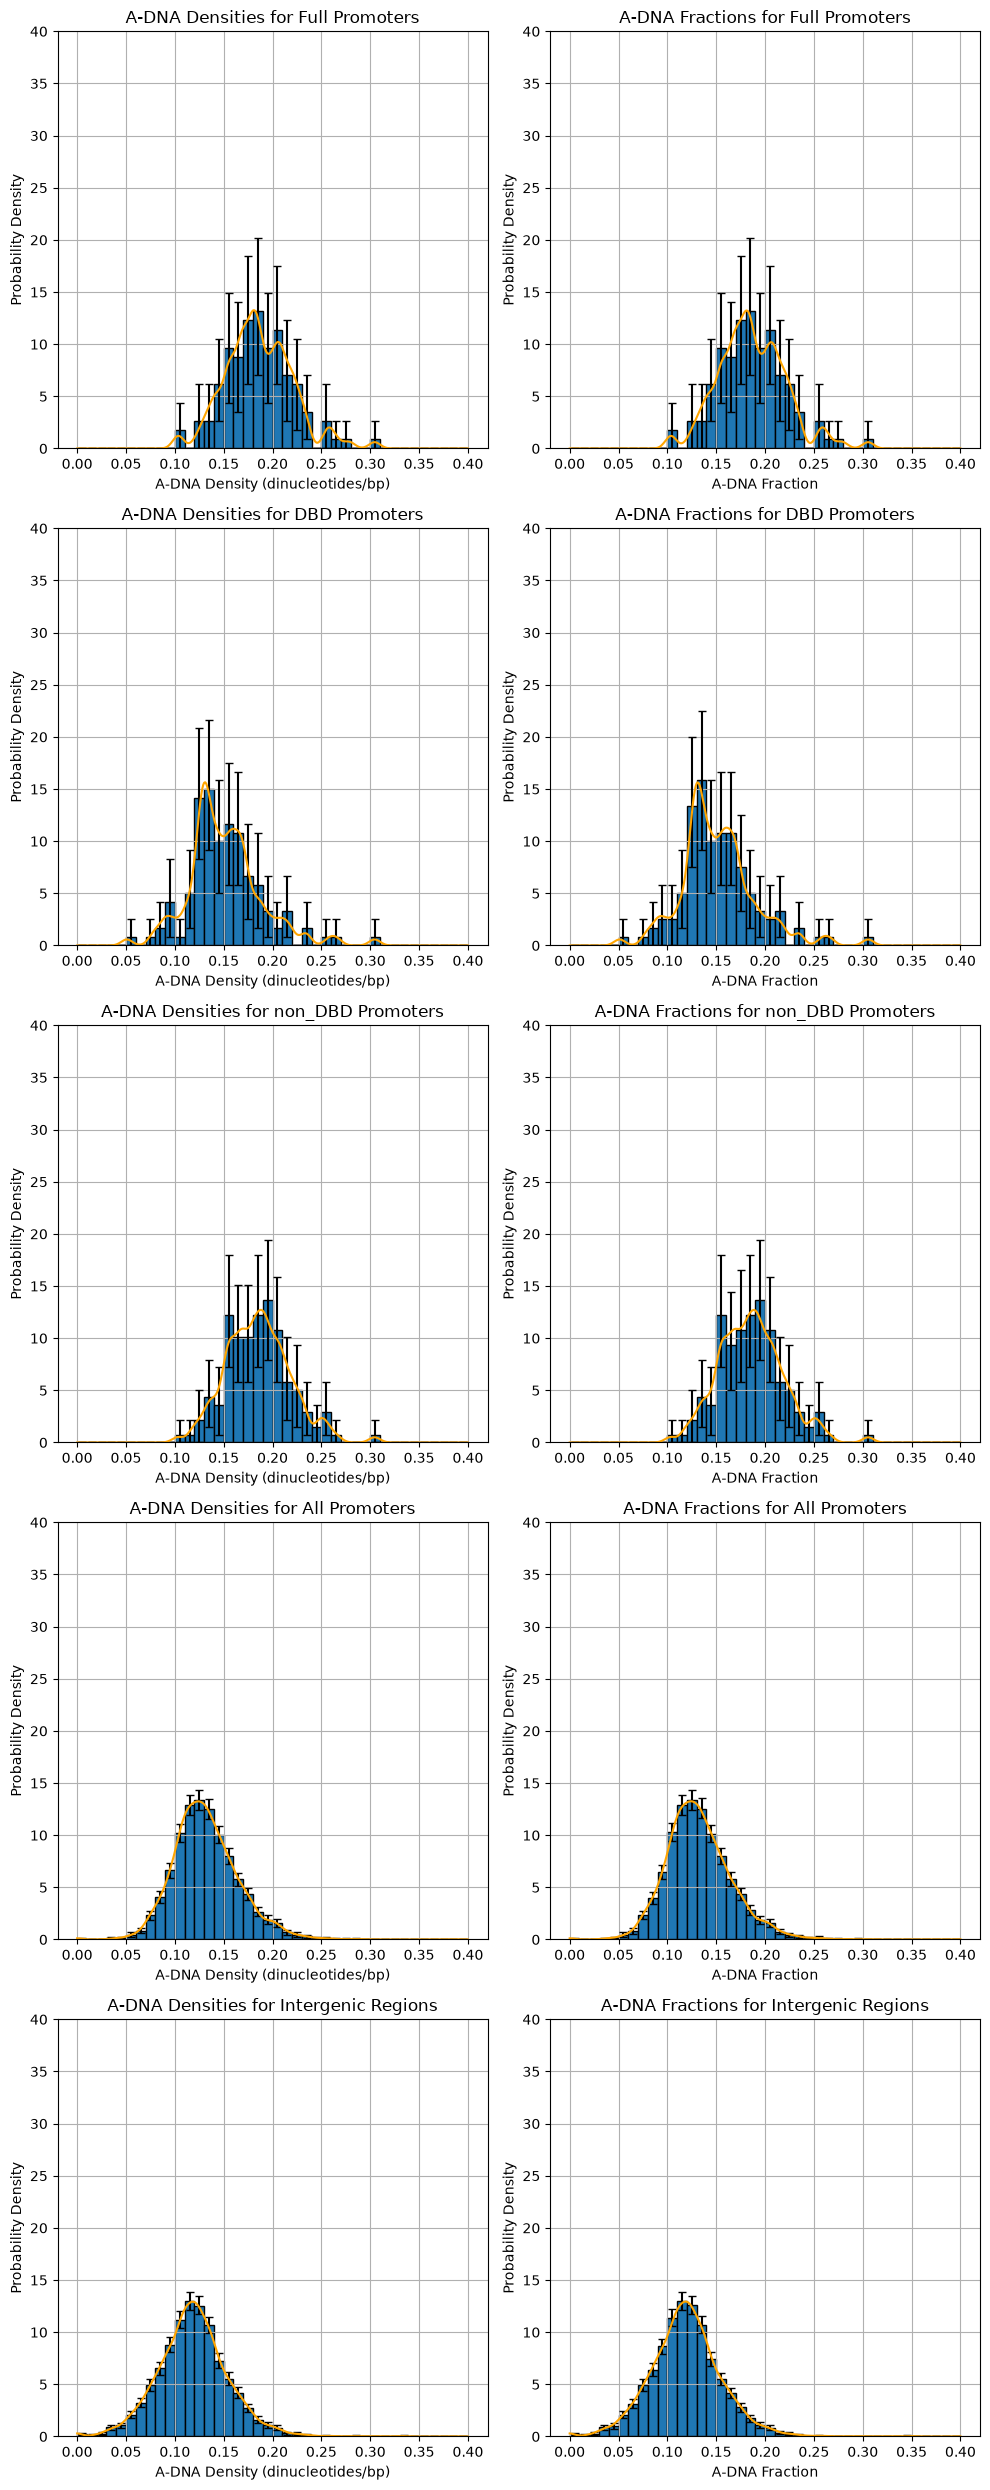

In [12]:
# construct distributions of relative A-DNA content and A-DND densities for each 
# construct/group        
bins = np.arange(0,0.41,0.01)
bin_width = bins[1] - bins[0]
bar_centers = bins[:-1]+(bin_width/2)
step = 0.001
grid = np.arange(0,0.4+step, step)
fig = plt.figure(figsize = [10,25])
idx = 1
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
num_constructs = len(constructs)
for construct in constructs:
    ax = fig.add_subplot(num_constructs,2, idx)
    idx += 1
    heights, bin_edges = np.histogram(a_dna_density_dict[construct], bins = bins, density = True)
    low_error_pos, high_error_pos = bin_errors(a_dna_density_dict[construct], bins)
    low_error = heights - low_error_pos
    high_error = np.clip(high_error_pos - heights, 0, None)
    error_array = np.vstack((low_error, high_error))
    ax.bar(bar_centers, heights, width = bin_width, yerr = error_array, edgecolor = 'k' , capsize = 3 )
    ax.plot(grid, a_dna_density_pdfs[construct], color = 'orange')
    ax.set_xlabel('A-DNA Density (dinucleotides/bp)')
    ax.set_ylabel('Probability Density')
    if 'NS' in construct:
        ax.set_title(f'A-DNA Densities for {construct} Sequences')
    elif construct == 'Intergenic':
        ax.set_title('A-DNA Densities for Intergenic Regions')
    else:
        ax.set_title(f'A-DNA Densities for {construct} Promoters')
    ax.set_ylim(0,40)
    ax.grid()
    ax = fig.add_subplot(num_constructs,2, idx)
    idx += 1
    heights, bin_edges = np.histogram(a_dna_fraction_dict[construct], bins = bins, density = True)
    low_error_pos, high_error_pos = bin_errors(a_dna_fraction_dict[construct], bins)
    low_error = heights - low_error_pos
    high_error = np.clip(high_error_pos - heights, 0, None)
    error_array = np.vstack((low_error, high_error))
    ax.bar(bar_centers, heights, width = bin_width, yerr = error_array, edgecolor = 'k', capsize = 3 )
    ax.plot(grid, a_dna_fraction_pdfs[construct], color = 'orange')
    ax.set_xlabel('A-DNA Fraction')
    ax.set_ylabel('Probability Density')
    if 'NS' in construct:
        ax.set_title(f'A-DNA Fractions for {construct} Sequences')
    elif construct == 'Intergenic':
        ax.set_title('A-DNA Fractions for Intergenic Regions')
    else:
        ax.set_title(f'A-DNA Fractions for {construct} Promoters')
    ax.set_ylim(0,40)
    ax.grid()
fig.tight_layout()
fig.savefig('A-DNA Density and Relative Content Distributions for All Constructs and Groups.png')

In [13]:
# now do the same thing but for different overlapping and unique target promoters
# first, find the A-DNA densities and relative A-DNA content of each promoter again

# make list of all the different promoter groups
promoter_groups = tuple(unique_promoters_dict.keys())
# create empty dictionaries to store each promoter groups data
promoter_groups_a_dna_density_dict = {}
promoter_groups_a_dna_fraction_dict = {}
# iterate over each group to get the promoters in each group
for promoter_group in promoter_groups:
    # grab the promoter information for that group
    promoters = unique_promoters_dict[promoter_group]
    # initialize variables to keep a running total of the number A-DNA dinucleotides and overall number of dinucleotides for the group
    tot_a_dna_dinuc = 0
    tot_2mer_count = 0
    # create empty lists to store the data for the group's promoters
    a_dna_density_list = []
    a_dna_fraction_list = []
    # iterate over each promoter in the group to calculate the density and relative content
    for promoter in promoters:
        # grab promoter information (chromosome,  left promoter coordinate, and right promoter coordinate, respectively)
        chrom, lc, rc = promoter
        # find the promoter sequence using the genome dictioary from earlier
        seq = genome_dict[chrom][lc:rc+1]
        # calculate sequence length
        seq_len  = len(seq)
        # calculate total number of dinucleotides in the promoter sequence
        tot_seq_dinucs = seq_len - 1
        # add number to running total for number of dinucleotides
        tot_2mer_count += tot_seq_dinucs
        # count the number of A-DNA dinucleotides
        CC_count = dinucleotide_counter(seq, 'CC')
        GG_count = dinucleotide_counter(seq, 'GG')
        CG_count = dinucleotide_counter(seq, 'CG')
        GC_count = dinucleotide_counter(seq, 'GC')
        seq_a_dna_dinuc_count = CC_count + GG_count + CG_count + GC_count
        # add number to running total of A-DNA dinucleotides
        tot_a_dna_dinuc += seq_a_dna_dinuc_count
        # calculate A-DNA density for the promoter sequence
        seq_a_dna_density = seq_a_dna_dinuc_count / seq_len
        # calculate relative A-DNA content for the promoter sequence
        seq_a_dna_fraction = seq_a_dna_dinuc_count / tot_seq_dinucs
        # append the density and relative content to their respective lists
        a_dna_density_list.append(seq_a_dna_density)
        a_dna_fraction_list.append(seq_a_dna_fraction)
    # add the lists with the data to the right dictionaries; each key is the promoter group and each value is its corresponding data
    promoter_groups_a_dna_density_dict[promoter_group] = np.array(a_dna_density_list)
    promoter_groups_a_dna_fraction_dict[promoter_group] = np.array(a_dna_fraction_list)
    # print out the number of A-DNA dinucleotides, total number of dinucleotdies, and proportion of A-DNA dinucleotides for the group
    print(f'For {promoter_group} promoters, there are {tot_a_dna_dinuc} A-DNA Dinucleotides out of {tot_2mer_count} total dinucleotides')
    print(f'Thus, A-DNA Dinucleotides make up {np.round((tot_a_dna_dinuc/tot_2mer_count)*100,2)}% of all dinucleotides in these promoters \n')

For DBD_only promoters, there are 6015 A-DNA Dinucleotides out of 42140 total dinucleotides
Thus, A-DNA Dinucleotides make up 14.27% of all dinucleotides in these promoters 

For Full_DBD promoters, there are 1650 A-DNA Dinucleotides out of 9596 total dinucleotides
Thus, A-DNA Dinucleotides make up 17.19% of all dinucleotides in these promoters 

For Shared promoters, there are 1759 A-DNA Dinucleotides out of 8510 total dinucleotides
Thus, A-DNA Dinucleotides make up 20.67% of all dinucleotides in these promoters 

For non_DBD_only promoters, there are 8338 A-DNA Dinucleotides out of 46456 total dinucleotides
Thus, A-DNA Dinucleotides make up 17.95% of all dinucleotides in these promoters 

For Full_only promoters, there are 3370 A-DNA Dinucleotides out of 18517 total dinucleotides
Thus, A-DNA Dinucleotides make up 18.2% of all dinucleotides in these promoters 

For Full_non_DBD promoters, there are 6703 A-DNA Dinucleotides out of 35560 total dinucleotides
Thus, A-DNA Dinucleotides mak

In [14]:
# now create pdfs for A-DNA density and Relative A-DNA Content for each promoter group
# first create global bandwidth for each metric
promoter_groups = tuple(unique_promoters_dict.keys())
master_promoter_group_density_data = [np.array(promoter_groups_a_dna_density_dict[i]) for i in promoter_groups]
master_promoter_group_fraction_data = [np.array(promoter_groups_a_dna_fraction_dict[i]) for i in promoter_groups]
master_promoter_group_density_data_array = np.concat(master_promoter_group_density_data)
master_promoter_group_fraction_data_array = np.concat(master_promoter_group_fraction_data)
promoter_group_density_bw = Scotts_rule_width(master_promoter_group_density_data_array)
promoter_group_fraction_bw = Scotts_rule_width(master_promoter_group_fraction_data_array)

# with global bandwidths for each metric, can now calculate the pdfs
# create empty dictionaries to hold pdfs for each metric 
promoter_group_a_dna_density_pdfs = {}
promoter_group_a_dna_fraction_pdfs = {}
# define the grid and step size for linear binning
step = 0.001
grid = np.arange(0,0.4+step, step)
# estimate the pdfs for each construct/group of interest
for idx, promoter_group in enumerate(promoter_groups):
    density_pdf = gkde(master_promoter_group_density_data[idx], grid, promoter_group_density_bw)
    fraction_pdf = gkde(master_promoter_group_fraction_data[idx], grid, promoter_group_fraction_bw)
    promoter_group_a_dna_density_pdfs[promoter_group] = density_pdf.ravel()
    promoter_group_a_dna_fraction_pdfs[promoter_group] = fraction_pdf.ravel()

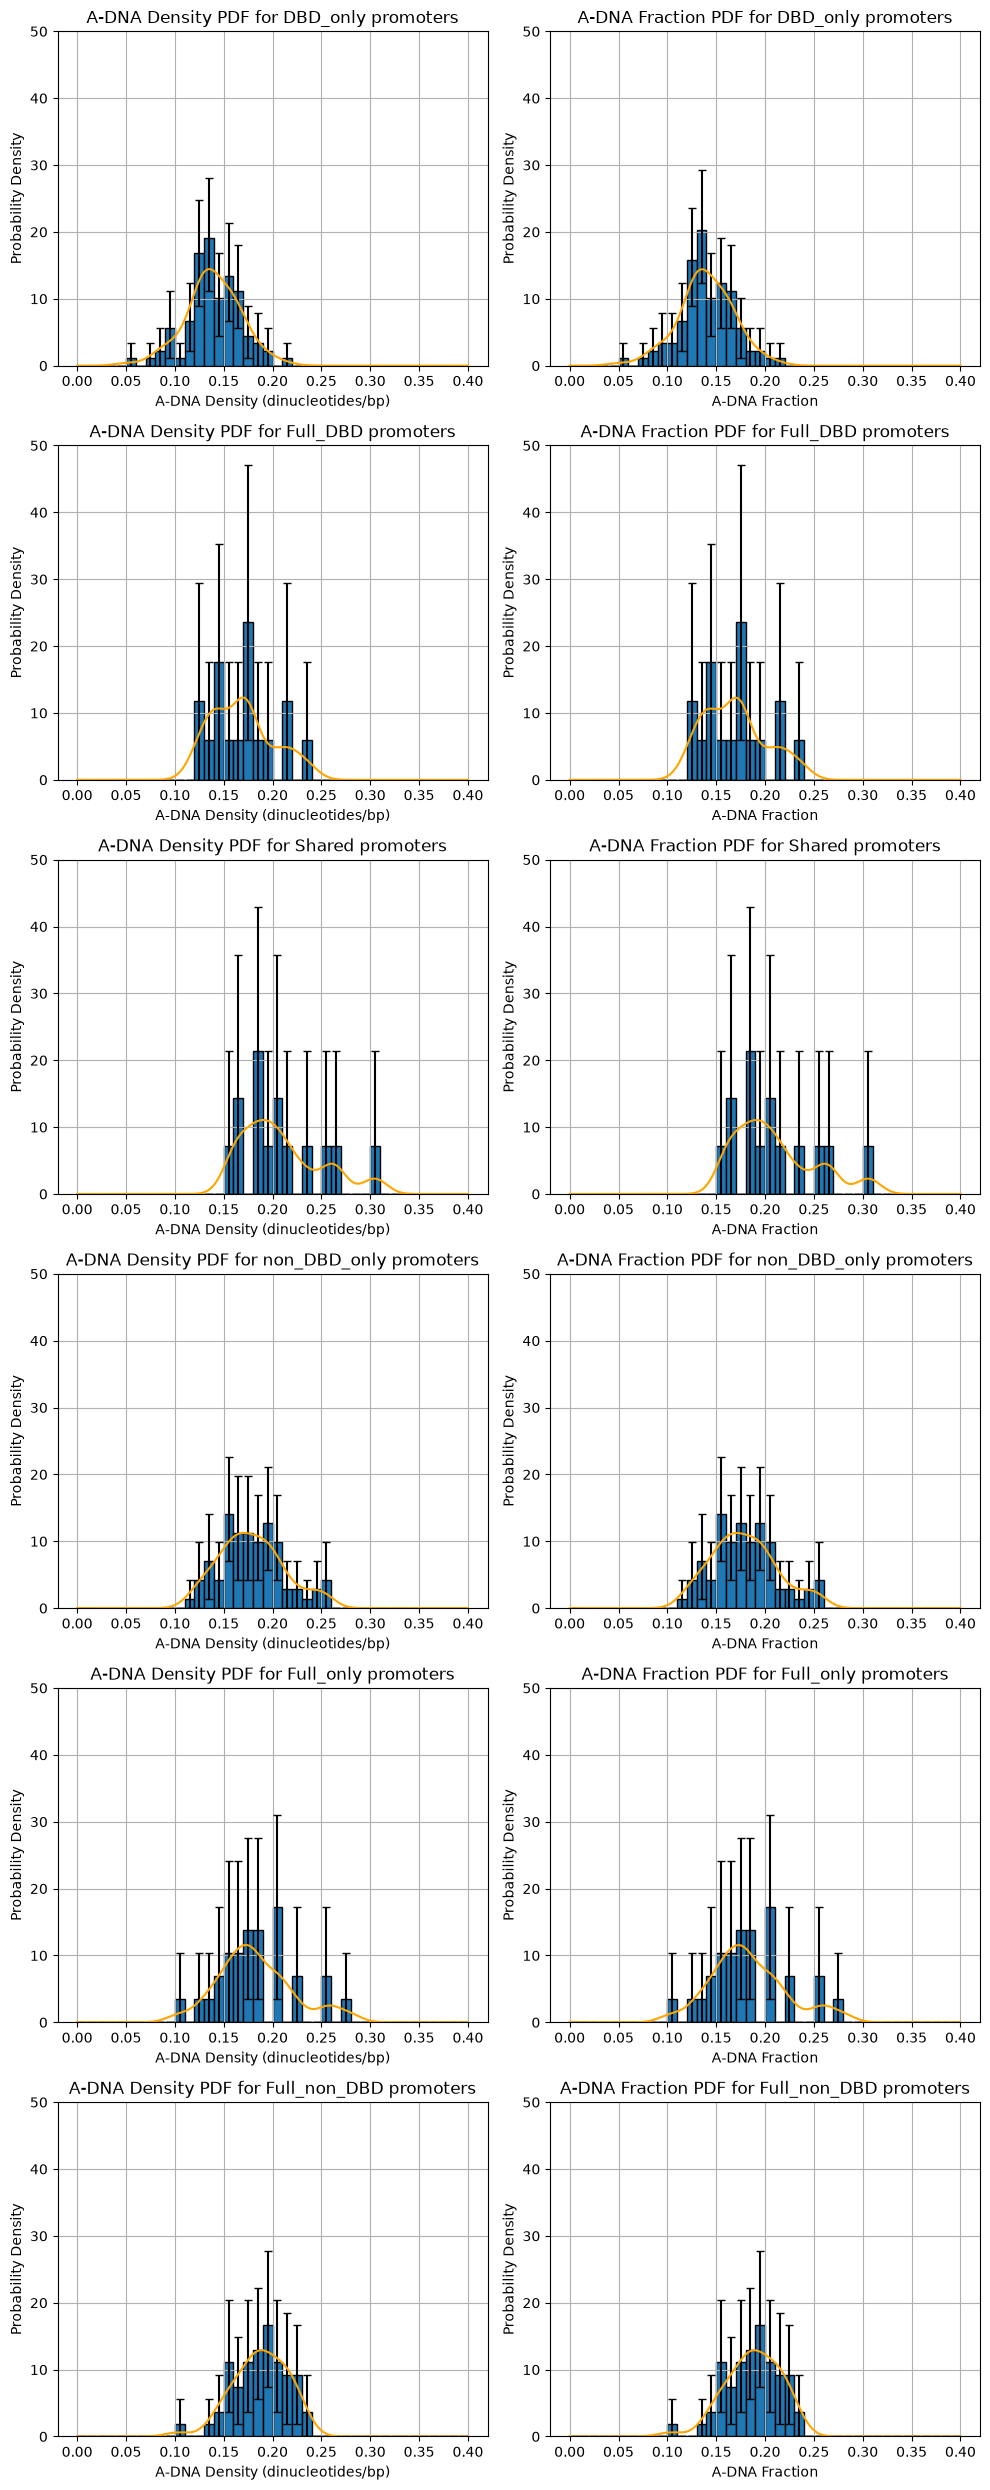

In [15]:
# now create pdfs for A-DNA density and Relative A-DNA Content for each promoter group
# first create global bandwidth for each metric
promoter_groups = tuple(unique_promoters_dict.keys())
master_promoter_group_density_data = np.concat([np.array(promoter_groups_a_dna_density_dict[i]) for i in promoter_groups])
master_promoter_group_fraction_data = np.concat([np.array(promoter_groups_a_dna_fraction_dict[i]) for i in promoter_groups])
promoter_group_density_bw = Scotts_rule_width(master_promoter_group_density_data)
promoter_group_fraction_bw = Scotts_rule_width(master_promoter_group_fraction_data)
step = 0.001
grid = np.arange(0,0.4+step, step)
bins = np.round(np.arange(0,0.41, 0.01),2)
idx = 1
plt.close()
fig = plt.figure(figsize = [10,25])

# make list of all the different promoter groups
for promoter_group in promoter_groups:
    ax = fig.add_subplot(len(promoter_groups),2, idx)
    idx += 1
    heights, bin_edges = np.histogram(promoter_groups_a_dna_density_dict[promoter_group], bins = bins, density = True)
    low_error_pos, high_error_pos = bin_errors(promoter_groups_a_dna_density_dict[promoter_group], bins)
    low_error = heights - low_error_pos
    high_error = np.clip(high_error_pos - heights, 0, None)
    error_array = np.vstack((low_error, high_error))
    ax.bar(bar_centers, heights, width = bin_width, yerr = error_array, edgecolor = 'k' , capsize = 3 )
    ax.plot(grid, promoter_group_a_dna_density_pdfs[promoter_group], color = 'orange')
    ax.set_xlabel('A-DNA Density (dinucleotides/bp)')
    ax.set_ylabel('Probability Density')
    ax.set_title(f'A-DNA Density PDF for {promoter_group} promoters')
    ax.set_ylim(0,50)
    ax.grid()
    ax = fig.add_subplot(len(promoter_groups),2, idx)
    idx += 1
    heights, bin_edges = np.histogram(promoter_groups_a_dna_fraction_dict[promoter_group], bins = bins, density = True)
    low_error_pos, high_error_pos = bin_errors(promoter_groups_a_dna_fraction_dict[promoter_group], bins)
    low_error = heights - low_error_pos
    high_error = np.clip(high_error_pos - heights, 0, None)
    error_array = np.vstack((low_error, high_error))
    ax.bar(bar_centers, heights, width = bin_width, yerr = error_array, edgecolor = 'k', capsize = 3 )
    ax.plot(grid, promoter_group_a_dna_fraction_pdfs [promoter_group], color = 'orange')
    ax.set_xlabel('A-DNA Fraction')
    ax.set_ylabel('Probability Density')
    ax.set_title(f'A-DNA Fraction PDF for {promoter_group} promoters')
    ax.set_ylim(0,50)
    ax.grid()
fig.tight_layout()
fig.savefig('A-DNA Density and Relative Content Distributions for All Promoter Overlap Groups.png')

From looking the A-DNA Dinucleotide densities and relative content between the different promoter groups, it seems like the Full_only promoters actually contain more A-DNA compared to both DBD_only and IDR_only promoters. More interestinlgy is that there are no promoters that are shared only DBD and IDR. If we take this into account with the fact that both the DBD only and IDR only promoters have slightly more relative A-DNA content than the promoters shared by all three groups, then perhaps each is finding A-DNA promoters differently. There just happens to be a number of A-DNA sequences near AGGGG motifs and if the IDR really can seek out A-DNA sequences, that could explain why it has higher relative A-DNA content promoters that do not overlap with the DBD.

Now we want to determine if the distributions for Full and IDR (non_DBD) promoters are statistically different (specificially, statistically enriched) from the other groups (DBD promoter, all promoters, and intergenic regions). We can do this by calculating the Kullback-Leibler Distance between each distribution then calulate a P-value for said distance using Monte Carlo Sampling as we have been doing. We shall take P-values < 0.05 to be significant. Then, we shall move to a heat map that indicates where the log-odds at each density/relative-content value are positive/negative to get a sense of if the difference in distriubution is due to more A-DNA or less A-DNA.

# P-values for Averages and Standard Deviations

In [16]:
def avg_error(data, num_bootstrap_samples = 10000, seed = 42):
    ndata = data.shape[0]
    rng = np.random.default_rng(seed)
    bootstrap_array = rng.choice(data, (num_bootstrap_samples,ndata))
    bootstrap_averages = np.mean(bootstrap_array, axis = 1, keepdims = True)
    low_error = np.percentile(bootstrap_averages, 2.5, keepdims = True)
    high_error = np.percentile(bootstrap_averages, 97.5, keepdims = True)
    return np.array([low_error, high_error]).reshape(-1,1)

def std_error(data, num_bootstrap_samples = 10000, seed = 42):
    ndata = data.shape[0]
    rng = np.random.default_rng(seed)
    bootstrap_array = rng.choice(data, (num_bootstrap_samples, ndata))
    bootstrap_means = np.mean(bootstrap_array, axis = 1, keepdims = True)
    bootstrap_means_2 = np.mean(bootstrap_array**2, axis = 1, keepdims = True)
    bootstrap_stds = np.sqrt(bootstrap_means_2 - bootstrap_means**2)
    low_error = np.percentile(bootstrap_stds, 2.5, keepdims = True)
    high_error = np.percentile(bootstrap_stds, 97.5, keepdims = True)
    return np.array([low_error, high_error]).reshape(-1,1)

In [17]:
a = np.array([[1,2], [3,4]])
print(np.sum(a, axis = 1))

[3 7]


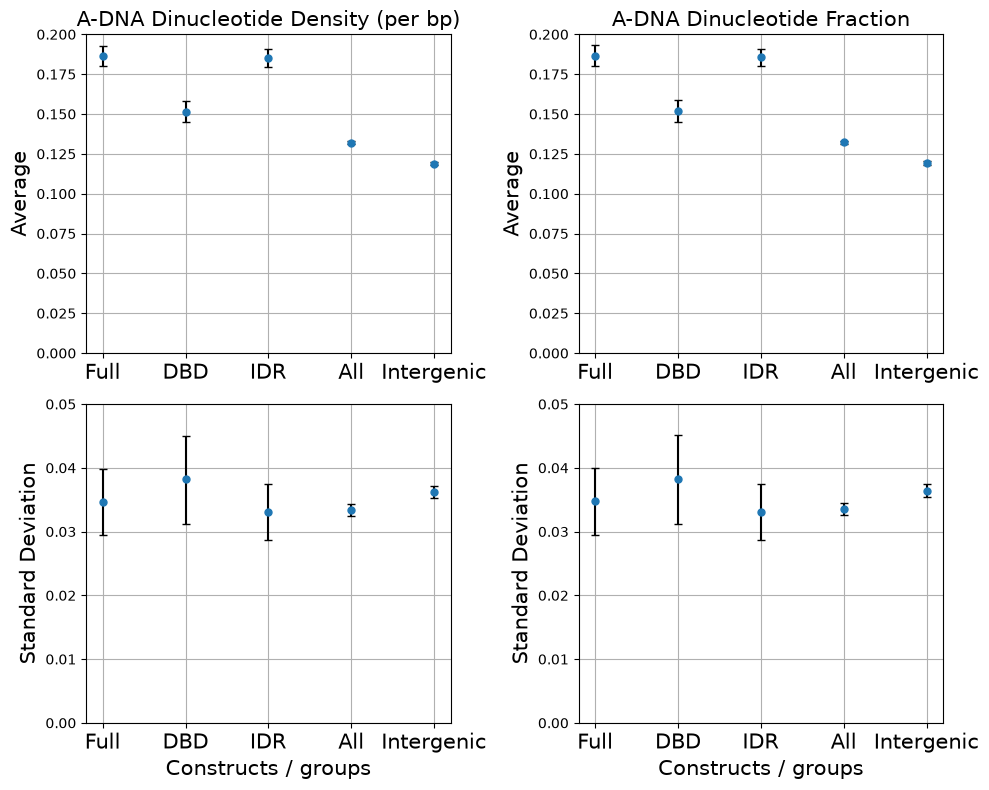

In [18]:
# before any p-value calculation and analysis, it would be good to have figures with just the plain averages and standard deviations
density_avgs = [np.mean(i) for i in master_density_data]
fraction_avgs = [np.mean(i) for i in master_fraction_data]
density_stds = [np.std(i) for i in master_density_data]
fraction_stds = [np.std(i) for i in master_fraction_data]
density_avgs_errors = np.hstack([avg_error(i) for i in master_density_data])
fraction_avgs_errors = np.hstack([avg_error(i) for i in master_fraction_data])
density_stds_errors = np.hstack([std_error(i) for i in master_density_data])
fraction_stds_errors = np.hstack([std_error(i) for i in master_fraction_data])
#constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
constructs = ['Full', 'DBD', 'IDR', 'All', 'Intergenic']
num_constructs = len(constructs)
x_pos = np.arange(1, 1+num_constructs,1)
fs = 15

fig = plt.figure(figsize = (10,8))
ax = fig.subplots(2,2)
for row_idx in range(2):
    if row_idx == 0:
        statistic = 'avgs'
        axis_stat_label = 'Average'
        y_max = 0.2
    else:
        statistic = 'stds'
        y_max = 0.05
        axis_stat_label = 'Standard Deviation'
    for col_idx in range(2):
        if col_idx == 0:
            metric = 'density'
            axis_metric_label = 'Density (per bp)'
        else:
            metric = 'fraction'
            axis_metric_label = 'Fraction'
        data_list = eval(metric+'_'+statistic)
        data_error = eval(metric+'_'+statistic+'_errors')
        error_magnitudes = np.abs(data_error - data_list)
        #ax[row_idx, col_idx].scatter(x_pos, data_list)
        ax[row_idx, col_idx].errorbar(x_pos, data_list, error_magnitudes, capsize = 3, linestyle = '', marker = '.', ecolor = 'k', markersize = 10)
        ax[row_idx, col_idx].set_xticks(x_pos, labels = constructs, size = fs)
        ax[row_idx, col_idx].set_ylim(0, y_max)
        ax[row_idx, col_idx].set_ylabel(axis_stat_label , fontsize = fs)
        ax[row_idx, col_idx].grid()
        if row_idx == 0:
            ax[row_idx, col_idx].set_title(f'A-DNA Dinucleotide {axis_metric_label}', fontsize = fs)
        else:
            ax[row_idx, col_idx].set_xlabel('Constructs / groups', fontsize = fs)
fig.tight_layout()
fig.savefig('Promoter A-DNA Content Statistics Bare Figure.png')

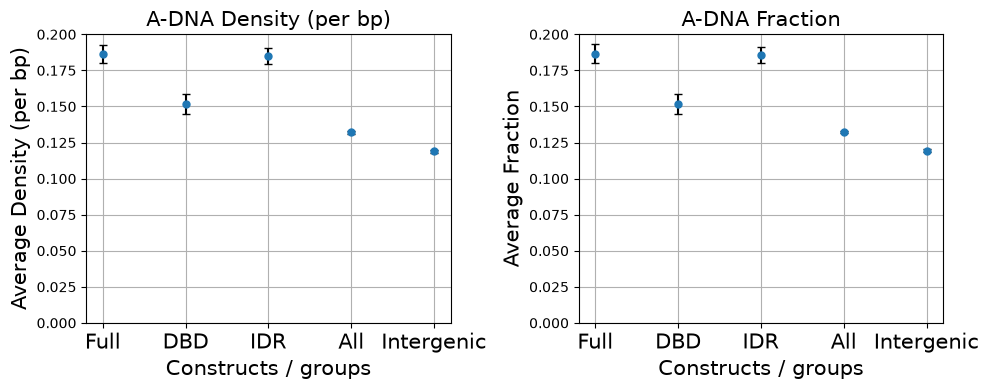

In [19]:
# before any p-value calculation and analysis, it would be good to have figures with just the plain averages and standard deviations
density_avgs = [np.mean(i) for i in master_density_data]
fraction_avgs = [np.mean(i) for i in master_fraction_data]
density_stds = [np.std(i) for i in master_density_data]
fraction_stds = [np.std(i) for i in master_fraction_data]
density_avgs_errors = np.hstack([avg_error(i) for i in master_density_data])
fraction_avgs_errors = np.hstack([avg_error(i) for i in master_fraction_data])
density_stds_errors = np.hstack([std_error(i) for i in master_density_data])
fraction_stds_errors = np.hstack([std_error(i) for i in master_fraction_data])
#constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
constructs = ['Full', 'DBD', 'IDR', 'All', 'Intergenic']
num_constructs = len(constructs)
x_pos = np.arange(1, 1+num_constructs,1)
fs = 15

fig = plt.figure(figsize = (10,4))
ax = fig.subplots(1,2)
for row_idx in range(1):
    if row_idx == 0:
        statistic = 'avgs'
        axis_stat_label = 'Average'
        y_max = 0.2
    else:
        statistic = 'stds'
        y_max = 0.05
        axis_stat_label = 'Standard Deviation'
    for col_idx in range(2):
        if col_idx == 0:
            metric = 'density'
            axis_metric_label = 'Density (per bp)'
        else:
            metric = 'fraction'
            axis_metric_label = 'Fraction'
        data_list = eval(metric+'_'+statistic)
        data_error = eval(metric+'_'+statistic+'_errors')
        error_magnitudes = np.abs(data_error - data_list)
        #ax[row_idx, col_idx].scatter(x_pos, data_list)
        ax[col_idx].errorbar(x_pos, data_list, error_magnitudes, capsize = 3, linestyle = '', marker = '.', ecolor = 'k', markersize = 10)
        ax[col_idx].set_xticks(x_pos, labels = constructs, size = fs)
        ax[col_idx].set_ylim(0, y_max)
        ax[col_idx].set_ylabel(axis_stat_label + ' ' + axis_metric_label , fontsize = fs)
        ax[col_idx].grid()
        ax[col_idx].set_title(f'A-DNA {axis_metric_label}', fontsize = fs)
        ax[col_idx].set_xlabel('Constructs / groups', fontsize = fs)
fig.tight_layout()
fig.savefig('Promoter A-DNA Content Averages.png')

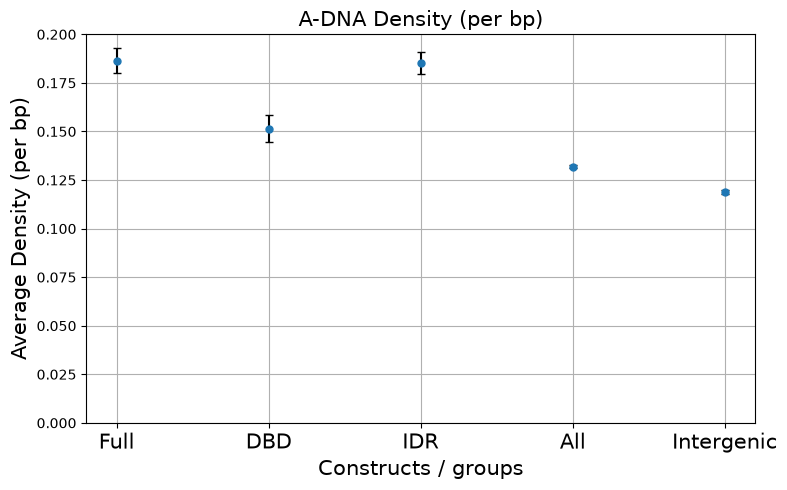

In [20]:
# before any p-value calculation and analysis, it would be good to have figures with just the plain averages and standard deviations
density_avgs = [np.mean(i) for i in master_density_data]
fraction_avgs = [np.mean(i) for i in master_fraction_data]
density_stds = [np.std(i) for i in master_density_data]
fraction_stds = [np.std(i) for i in master_fraction_data]
density_avgs_errors = np.hstack([avg_error(i) for i in master_density_data])
fraction_avgs_errors = np.hstack([avg_error(i) for i in master_fraction_data])
density_stds_errors = np.hstack([std_error(i) for i in master_density_data])
fraction_stds_errors = np.hstack([std_error(i) for i in master_fraction_data])
#constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
constructs = ['Full', 'DBD', 'IDR', 'All', 'Intergenic']
num_constructs = len(constructs)
x_pos = np.arange(1, 1+num_constructs,1)
fs = 15

fig = plt.figure(figsize = (8,5))
ax = fig.subplots(1,1)
for row_idx in range(1):
    if row_idx == 0:
        statistic = 'avgs'
        axis_stat_label = 'Average'
        y_max = 0.2
    else:
        statistic = 'stds'
        y_max = 0.05
        axis_stat_label = 'Standard Deviation'
    for col_idx in range(1):
        if col_idx == 0:
            metric = 'density'
            axis_metric_label = 'Density (per bp)'
        else:
            metric = 'fraction'
            axis_metric_label = 'Fraction'
        data_list = eval(metric+'_'+statistic)
        data_error = eval(metric+'_'+statistic+'_errors')
        error_magnitudes = np.abs(data_error - data_list)
        #ax[row_idx, col_idx].scatter(x_pos, data_list)
        ax.errorbar(x_pos, data_list, error_magnitudes, capsize = 3, linestyle = '', marker = '.', ecolor = 'k', markersize = 10)
        ax.set_xticks(x_pos, labels = constructs, size = fs)
        ax.set_ylim(0, y_max)
        ax.set_ylabel(axis_stat_label + ' ' + axis_metric_label , fontsize = fs)
        ax.grid()
        ax.set_title(f'A-DNA {axis_metric_label}', fontsize = fs)
        ax.set_xlabel('Constructs / groups', fontsize = fs)
fig.tight_layout()
fig.savefig('Promoter A-DNA Density Average.png')

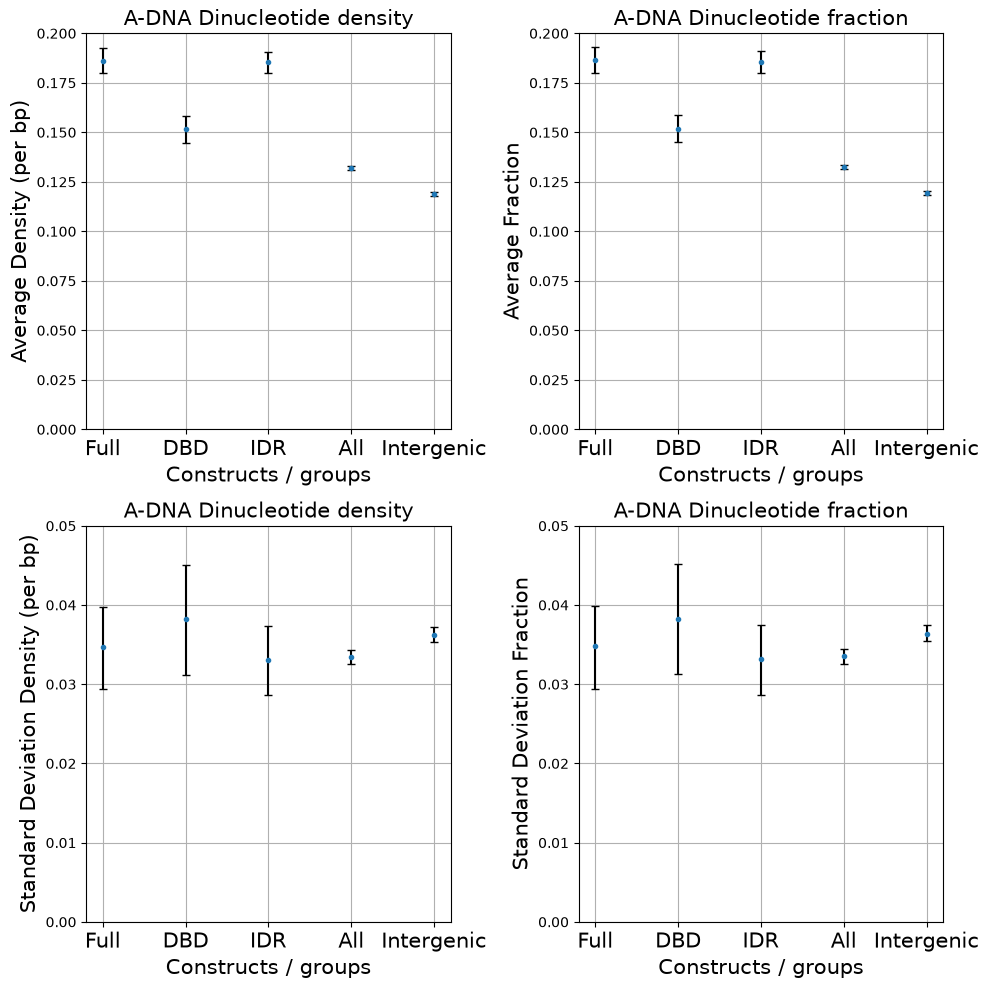

In [21]:
# before any p-value calculation and analysis, it would be good to have figures with just the plain averages and standard deviations
density_avgs = [np.mean(i) for i in master_density_data]
fraction_avgs = [np.mean(i) for i in master_fraction_data]
density_stds = [np.std(i) for i in master_density_data]
fraction_stds = [np.std(i) for i in master_fraction_data]
density_avgs_errors = np.hstack([avg_error(i) for i in master_density_data])
fraction_avgs_errors = np.hstack([avg_error(i) for i in master_fraction_data])
density_stds_errors = np.hstack([std_error(i) for i in master_density_data])
fraction_stds_errors = np.hstack([std_error(i) for i in master_fraction_data])
#constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
constructs = ['Full', 'DBD', 'IDR', 'All', 'Intergenic']
num_constructs = len(constructs)
x_pos = np.arange(1, 1+num_constructs,1)
fs = 15

fig = plt.figure(figsize = (10,10))
ax = fig.subplots(2,2)
for row_idx in range(2):
    if row_idx == 0:
        statistic = 'avgs'
        axis_stat_label = 'Average'
        y_max = 0.2
    else:
        statistic = 'stds'
        y_max = 0.05
        axis_stat_label = 'Standard Deviation'
    for col_idx in range(2):
        if col_idx == 0:
            metric = 'density'
            axis_metric_label = 'Density (per bp)'
        else:
            metric = 'fraction'
            axis_metric_label = 'Fraction'
        data_list = eval(metric+'_'+statistic)
        data_error = eval(metric+'_'+statistic+'_errors')
        error_magnitudes = np.abs(data_error - data_list)
        #ax[row_idx, col_idx].scatter(x_pos, data_list)
        ax[row_idx, col_idx].errorbar(x_pos, data_list, error_magnitudes, capsize = 3, linestyle = '', marker = '.', ecolor = 'k')
        ax[row_idx, col_idx].set_xticks(x_pos, labels = constructs, size = fs)
        ax[row_idx, col_idx].set_ylim(0, y_max)
        ax[row_idx, col_idx].set_ylabel(axis_stat_label + ' ' + axis_metric_label, fontsize = fs)
        ax[row_idx, col_idx].grid()
        ax[row_idx, col_idx].set_title(f'A-DNA Dinucleotide {metric}', fontsize = fs)
        ax[row_idx, col_idx].set_xlabel('Constructs / groups', fontsize = fs)
fig.tight_layout()
fig.savefig('Promoter A-DNA Content Statistics.png')

In [22]:
def avg_std_MC_ref_math(coi_1d_array, ref_1d_array, mc_indices_array):
    '''
    Function that does all the math and numpy operations for calculating the reference averages and standard deviations between 
    two constructs. This function was specifically made to be speed up by numba since trying to speed things up by numpy vectorization
    was not fast enough.
    
    Parameters
    ----------
    coi_1d_array : 1D numpy ndarray
        1D Array containing the data for the construct of interest.
    ref_1d_array : 1D numpy ndarray
        1D Array containing the data for the construct to be used as the reference.
    mc_indicies_array : 2d numpy ndarray
        2D numpy array where the number of rows is the number of MC samples taken and each row represents a random mixing of the data from
        both constructs.
    avg_diff_ref_array, std_diff_ref_array : 2d numpy ndarrays
        Empty (contain only zeros) arrays for holding the differences between averages and standard deviations for each MC sample
    Returns
    -------
    avg_diff_ref_array: 1D numpy ndarray
        1D numpy array holding the reference average differences. The array has the same number of rows as mc_indicies_array
        representing the set of reference aveage differences. Each element is then a referenc average difference to be used for 
        constructing p-values.
    std_diff_ref_array: 1D numpy ndarray
        Exactly the same as above but for the difference between standard deviations.
    '''
    # grab the number number of coi promoters/sequences
    coi_num_seqs = coi_1d_array.shape[0]
    # grab the number of ref promoters/sequences 
    ref_num_seqs = ref_1d_array.shape[0]
    # calculate the total number of sequences between coi and ref constructs/groups
    tot_num_seqs = int(coi_num_seqs + ref_num_seqs)
    # grab number of MC samples for mc_indices_array
    num_MC_samples = mc_indices_array.shape[0]
    # put all of the data into a single 1D array
    master_data_array = np.concat((coi_1d_array, ref_1d_array))
    # use mc_indicies_array to create 2D array where each column is a MC sample
    mc_samples = master_data_array[mc_indices_array]
    # split mc_samples into "coi" and "ref" groups
    coi_mc_samples = mc_samples[:, :coi_num_seqs]
    ref_mc_samples = mc_samples[:, coi_num_seqs:]
    # calculate the means of the groups
    coi_mc_means = np.mean(coi_mc_samples, axis = 1, keepdims = True)
    ref_mc_means = np.mean(ref_mc_samples, axis = 1, keepdims = True)
    # square the mc samples and calculate the mean of each group
    coi_mc_means_2 = np.mean(coi_mc_samples**2, axis = 1, keepdims = True)
    ref_mc_means_2 = np.mean(ref_mc_samples**2, axis = 1, keepdims = True)
    # calculate the standard deviations using the previously calculate means
    coi_mc_stds = np.sqrt(coi_mc_means_2 - coi_mc_means**2)
    ref_mc_stds = np.sqrt(ref_mc_means_2 - ref_mc_means**2)
    # calculate the differences between averages and standard deviations
    avg_diff_refs = coi_mc_means - ref_mc_means
    std_diff_refs = coi_mc_stds - ref_mc_stds
    return avg_diff_refs, std_diff_refs

def avg_std_MC_ref_calc(coi_1d_array, ref_1d_array,  num_MC_samples = 10000, seed = 42):
    '''
    Function that calculates reference averages and standard deviations between two constructs for all A-DNA subsequence lengths and A-DNA 
    probability thresholds.
    
    Parameters
    ----------
    coi_1d_array : 1D numpy ndarray
        1D Array containing the data for the construct of interest.
    ref_1d_array : 1D numpy ndarray
        1D Array containing the data for the construct to be used as the reference.
    num_MC_samples : int (default : 10,000)
        Number of times to perform Monte Carlo sampling to generate a new set of groups. It essentially represents how many reference KL
        distances to calculate. The default value is 10,000.
    seed : int (default : 42)
        Random seed for random generate used in Monte Carlo sampling. Default is 42; seed helps ensure that randomization is the same every
        time thereby allowing for reproducibile results.
    Returns
    -------
    avg_diff_ref_array: 1D numpy ndarray
        1D numpy array holding the reference average differences. The array has the same number of rows as mc_indicies_array
        representing the set of reference aveage differences. Each element is then a referenc average difference to be used for 
        constructing p-values.
    std_diff_ref_array: 1D numpy ndarray
        Exactly the same as above but for the difference between standard deviations.
    '''
    # grab the number of coi promoters/sequences
    coi_num_seqs = coi_1d_array.shape[0]
    # grab the number of ref_sequences 
    ref_num_seqs = ref_1d_array.shape[0]
    # calculate the total number of sequences between coi and ref constructs/groups
    tot_num_seqs = int(coi_num_seqs + ref_num_seqs)
    # create the numpy Random Generator for the Monte Carlo Sampling
    rng = np.random.default_rng(seed)
    # create an array with the indices for all sequences in coi and ref;
    indices_array = np.tile(np.arange(tot_num_seqs, dtype = np.int64), (num_MC_samples,1))
    # independently shuffle the indices in each row to create 10,000 new sequences of indices
    # doing this before KL distance calculations ensures that the same randomized groups are looked for each threshold
    mc_indices_array = rng.permuted(indices_array, axis = 1)
    avg_diff_ref_array, std_diff_ref_array = avg_std_MC_ref_math(coi_1d_array, ref_1d_array, mc_indices_array)
    return avg_diff_ref_array, std_diff_ref_array

def avg_std_p_values_calc(coi, ref, metric, null_hypothesis, num_MC_samples = 10000, seed = 42):
    '''
    Function that calculates the p-values for the difference in average and standard deviation of a metric between two constructs denoted 
    by coi and ref. This is done by creating a reference distribution for these statistics. The function allow for the user to specify if
    they want to do a two-tailed p-value or one-tailed p-value.

    Parameters
    ----------
    coi : string ('Full', 'DBD', 'non_DBD', 'All', 'Intergenic')
        Construct of interest / construct to use as the sample/
    ref : string ('Full', 'DBD', 'non_DBD', 'All', 'Intergenic')
        Construct/group to use for as a reference
    metric : string ('A-DNA Densities', 'A-DNA Fractions')
        String indicating whether to look at the A-DNA Densities (number of A-DNA dinucleotides / seqeunce length) or A-DNA Fractions 
        (number of A-DNA dinucleotides / number of total dinucleotides in sequence)
    null_hypothesis : string ('Larger', 'Smaller', 'Different')
        String indicating what the null hypothesis is. If 'Different', the null hypothesis is "these statistics are statistiacally the
        same" and a two-tailed p-value will be computed. If 'Larger', the null hypothesis is "the coi does not have a statistically larger
        mean/standard deviation compared to the ref" and one-tailed p-value (for the right side of the distribution) will be computed. If
        'Smaller', the null hypothesis is "the coi does not have a statistically smaller mean/standard deviation compared to the ref" and a
        one-tailed p-value (for the left side of the distribution) will be computed.
    num_MC_samples : int (default : 10,000)
        Number of times to perform Monte Carlo sampling to generate a new set of groups. It essentially represents how many reference KL
        distances to calculate. The default value is 10,000.
    seed : int (default : 42)
        Random seed for random generate used in Monte Carlo sampling. Default is 42; seed helps ensure that randomization is the same every
        time thereby allowing for reproducibile results.
    
    Return 
    ------
    '''
    # grab the right data depending on the metric supplied
    if 'Densities' in metric:
        coi_1d_array = a_dna_density_dict[coi]
        ref_1d_array = a_dna_density_dict[ref]
    else:
        coi_1d_array = a_dna_fraction_dict[coi]
        ref_1d_array = a_dna_fraction_dict[ref]        
    # calculate the average and standard deviation differences between the sample and reference constructs
    avg_diff_orig = np.mean(coi_1d_array) - np.mean(ref_1d_array)
    std_diff_orig = np.abs(np.std(coi_1d_array) - np.std(ref_1d_array))
    # calculate reference average and standard deviation differences betwen the sample and reference constructs
    avg_diff_ref, std_diff_ref = avg_std_MC_ref_calc(coi_1d_array, ref_1d_array, num_MC_samples, seed)
    # use the reference KL distances to calculate p-values for the KL distances between the sample and reference constructs
    # if the null hypothesis is about the difference between groups, find the two-tailed p-values
    if null_hypothesis == 'Different':
        avg_p_values = (np.sum(np.where(np.abs(avg_diff_ref) >= np.abs(avg_diff_orig), 1, 0)))/num_MC_samples
        std_p_values = (np.sum(np.where(np.abs(std_diff_ref) >= np.abs(std_diff_orig), 1, 0)))/num_MC_samples
    # if the null hypothesis is about who is bigger, find the one-tailed p-values to the right of the distribution
    elif null_hypothesis == 'Larger':
        avg_p_values = (np.sum(np.where(avg_diff_ref >= avg_diff_orig, 1, 0)))/num_MC_samples
        std_p_values = (np.sum(np.where(std_diff_ref >= std_diff_orig, 1, 0)))/num_MC_samples
    # if the null hypothesis is about who is smaller, find the one-tailed p-values to the left of the distribution
    elif null_hypothesis == 'Smaller':
        avg_p_values = (np.sum(np.where(avg_diff_ref <= avg_diff_orig, 1, 0)))/num_MC_samples
        std_p_values = (np.sum(np.where(std_diff_ref <= std_diff_orig, 1, 0)))/num_MC_samples
    return avg_p_values, std_p_values

It took 13.685868978500366 seconds to calculate all p-values


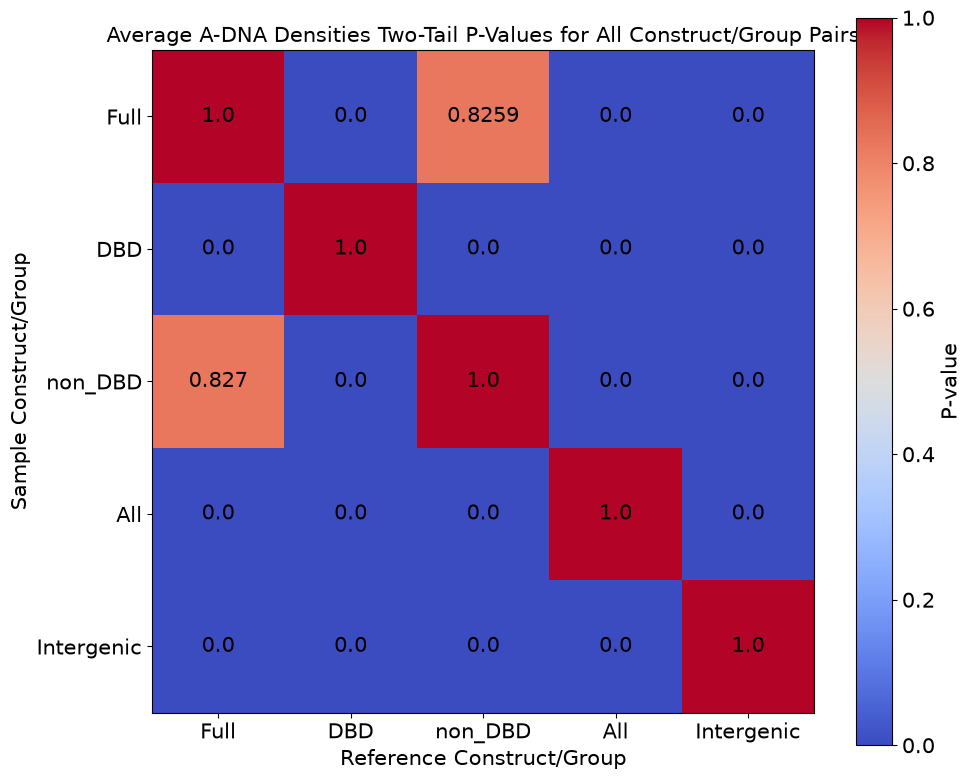

In [23]:
ts = time()
fs = 15
metric = 'A-DNA Densities'
null_hypothesis = 'Different'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[0]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = constructs, size = fs)
ax.set_yticks(range(num_constructs), labels = constructs, size = fs)
ax.set_ylabel('Sample Construct/Group', fontsize = fs)
ax.set_xlabel('Reference Construct/Group', fontsize = fs)
ax.set_title('Average ' + metric + ' Two-Tail P-Values for All Construct/Group Pairs', fontsize = fs)
cbar = fig.colorbar(im, ax = ax, shrink = 0.75)
cbar.ax.tick_params(labelsize = fs)
cbar.ax.set_ylabel('P-value', fontsize = fs)
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_avg_p_value_array[y,x], ha = 'center', va = 'center', fontsize = fs)
fig.tight_layout()
fig.savefig('A-DNA Dinucleotide Densities Avg Two Tail P-values Heatmap.png')

It took 13.70196008682251 seconds to calculate all p-values


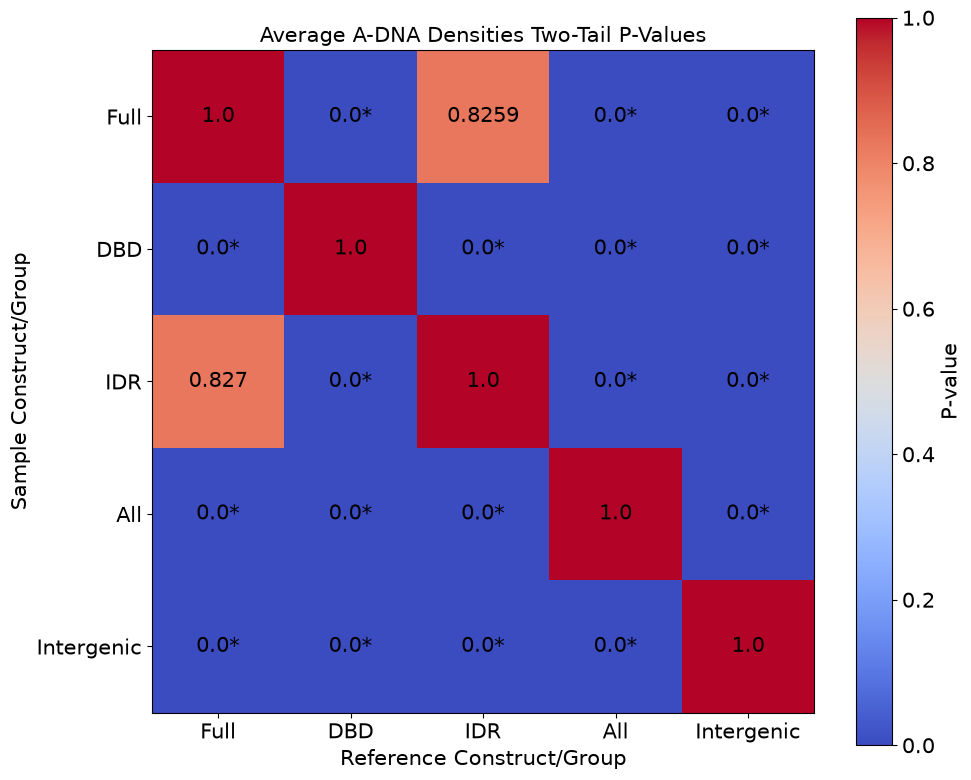

In [24]:
ts = time()
fs = 15
metric = 'A-DNA Densities'
null_hypothesis = 'Different'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
construct_labels = ['Full', 'DBD', 'IDR', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[0]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = construct_labels, size = fs)
ax.set_yticks(range(num_constructs), labels = construct_labels, size = fs)
ax.set_ylabel('Sample Construct/Group', fontsize = fs)
ax.set_xlabel('Reference Construct/Group', fontsize = fs)
ax.set_title('Average ' + metric + ' Two-Tail P-Values', fontsize = fs)

cbar = fig.colorbar(im, ax = ax, shrink = 0.75)
cbar.ax.tick_params(labelsize = fs)
cbar.ax.set_ylabel('P-value', fontsize = fs)
for y in range(num_constructs):
    for x in range(num_constructs):
        p_val = a_dna_density_avg_p_value_array[y,x]
        if p_val < 0.05:
            p_val_str = str(p_val) + '*'
        else:
            p_val_str = str(p_val)
        ax.text(x,y, p_val_str, ha = 'center', va = 'center', fontsize = fs)
fig.tight_layout()
fig.savefig('A-DNA Dinucleotide Densities Avg Two Tail P-values Heatmap Presentation Style.png')

It took 13.601763725280762 seconds to calculate all p-values


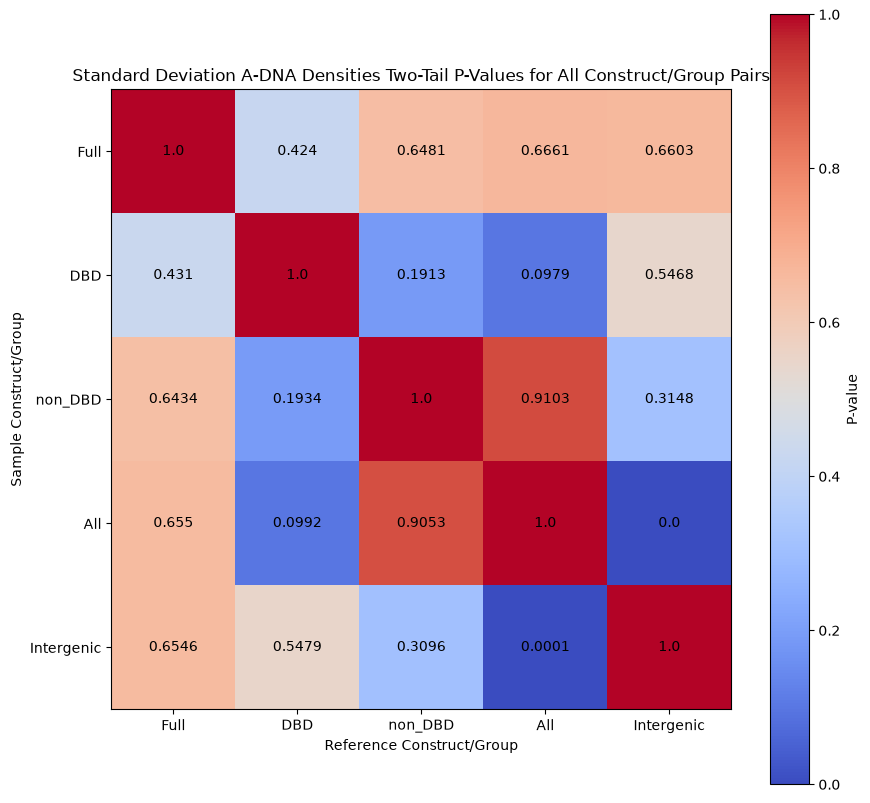

In [25]:
ts = time()
metric = 'A-DNA Densities'
null_hypothesis = 'Different'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[1]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = constructs)
ax.set_yticks(range(num_constructs), labels = constructs)
ax.set_ylabel('Sample Construct/Group')
ax.set_xlabel('Reference Construct/Group')
ax.set_title('Standard Deviation ' + metric + ' Two-Tail P-Values for All Construct/Group Pairs')
cbar = fig.colorbar(im, ax = ax, label = 'P-value')
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_avg_p_value_array[y,x], ha = 'center', va = 'center')
fig.savefig('A-DNA Dinucleotide Densities Std Two Tail P-values Heatmap.png')

It took 13.618127822875977 seconds to calculate all p-values


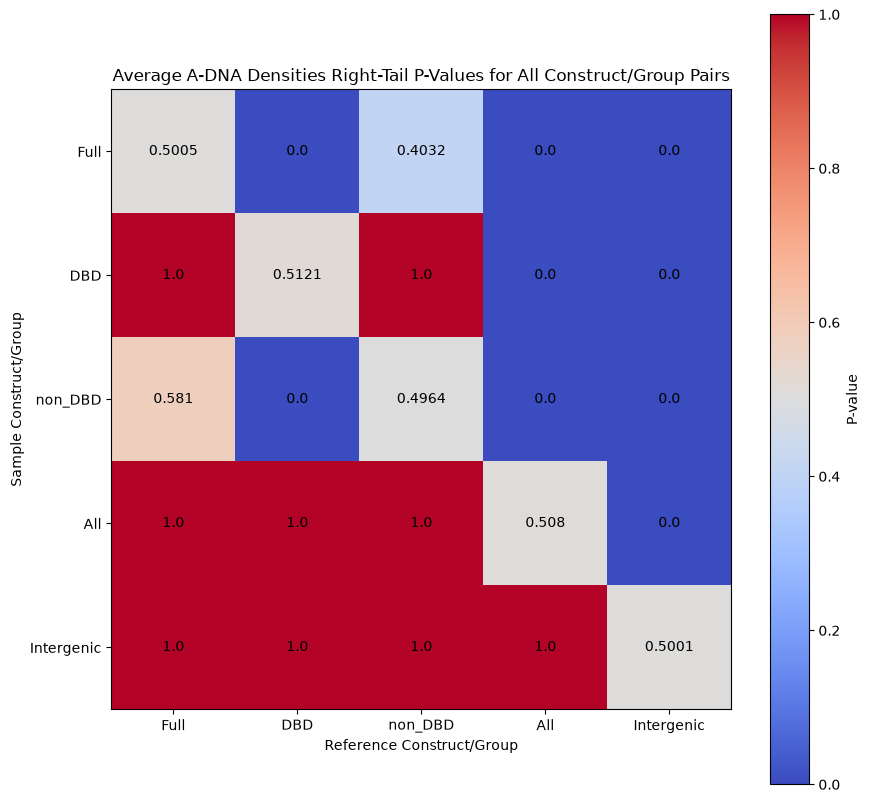

In [26]:
ts = time()
metric = 'A-DNA Densities'
null_hypothesis = 'Larger'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[0]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = constructs)
ax.set_yticks(range(num_constructs), labels = constructs)
ax.set_ylabel('Sample Construct/Group')
ax.set_xlabel('Reference Construct/Group')
ax.set_title('Average ' + metric + ' Right-Tail P-Values for All Construct/Group Pairs')
cbar = fig.colorbar(im, ax = ax, label = 'P-value')
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_avg_p_value_array[y,x], ha = 'center', va = 'center')
fig.savefig('A-DNA Dinucleotide Densities Avg Right Tail P-values Heatmap.png')

It took 13.596296072006226 seconds to calculate all p-values


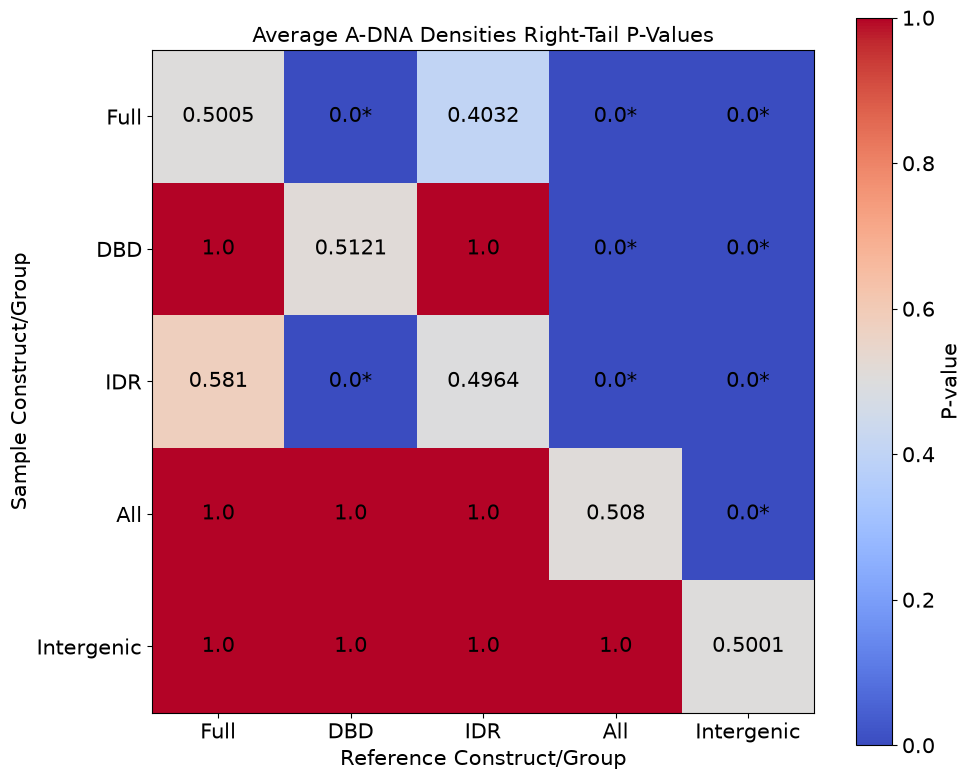

In [27]:
ts = time()
fs = 15
metric = 'A-DNA Densities'
null_hypothesis = 'Larger'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
construct_labels = ['Full', 'DBD', 'IDR', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[0]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = construct_labels, size = fs)
ax.set_yticks(range(num_constructs), labels = construct_labels, size = fs)
ax.set_ylabel('Sample Construct/Group', fontsize = fs)
ax.set_xlabel('Reference Construct/Group', fontsize = fs)
ax.set_title('Average ' + metric + ' Right-Tail P-Values', fontsize = fs)

cbar = fig.colorbar(im, ax = ax, shrink = 0.75)
cbar.ax.tick_params(labelsize = fs)
cbar.ax.set_ylabel('P-value', fontsize = fs)
for y in range(num_constructs):
    for x in range(num_constructs):
        p_val = a_dna_density_avg_p_value_array[y,x]
        if p_val < 0.05:
            p_val_str = str(p_val) + '*'
        else:
            p_val_str = str(p_val)
        ax.text(x,y, p_val_str, ha = 'center', va = 'center', fontsize = fs)
fig.tight_layout()
fig.savefig('A-DNA Dinucleotide Densities Avg Right Tail P-values Heatmap Presentation Style.png')

It took 13.617456436157227 seconds to calculate all p-values


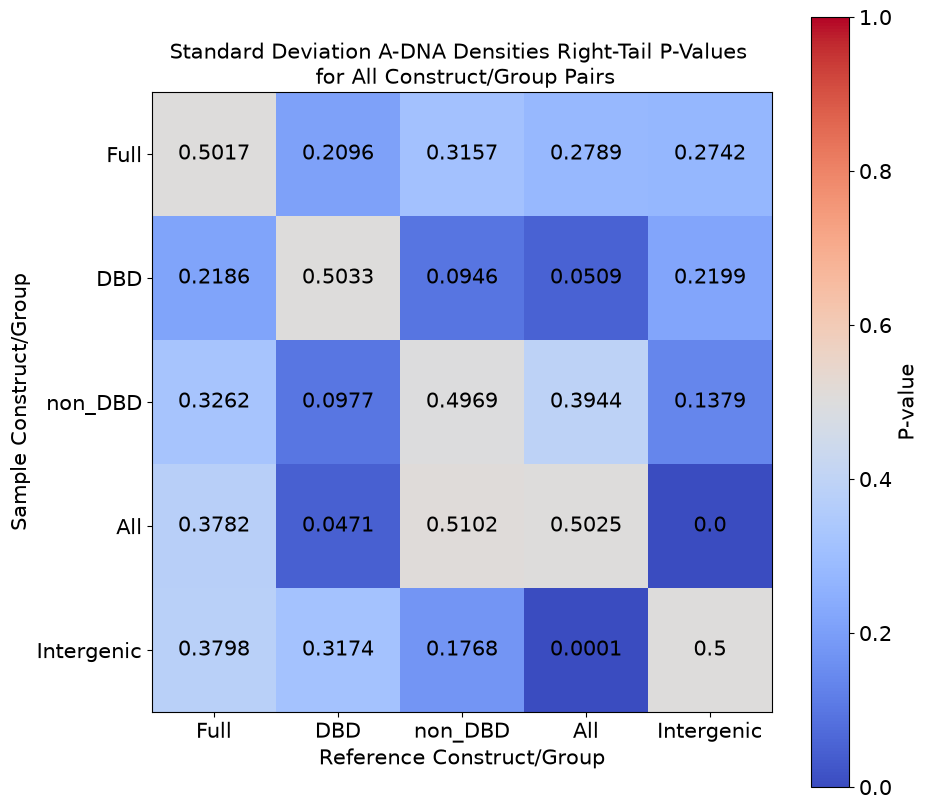

In [28]:
ts = time()
fs = 15
metric = 'A-DNA Densities'
null_hypothesis = 'Larger'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[1]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = constructs, size = fs)
ax.set_yticks(range(num_constructs), labels = constructs, size = fs)
ax.set_ylabel('Sample Construct/Group', fontsize = fs)
ax.set_xlabel('Reference Construct/Group', fontsize = fs)
ax.set_title('Standard Deviation ' + metric + ' Right-Tail P-Values \n for All Construct/Group Pairs', fontsize = fs)

cbar = fig.colorbar(im, ax = ax, label = 'P-value')
cbar.ax.tick_params(labelsize = fs)
cbar.ax.set_ylabel('P-value', fontsize = fs)
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_avg_p_value_array[y,x], ha = 'center', va = 'center', fontsize = fs)
fig.savefig('A-DNA Dinucleotide Densities Std Right Tail P-values Heatmap.png')

It took 13.530076026916504 seconds to calculate all p-values


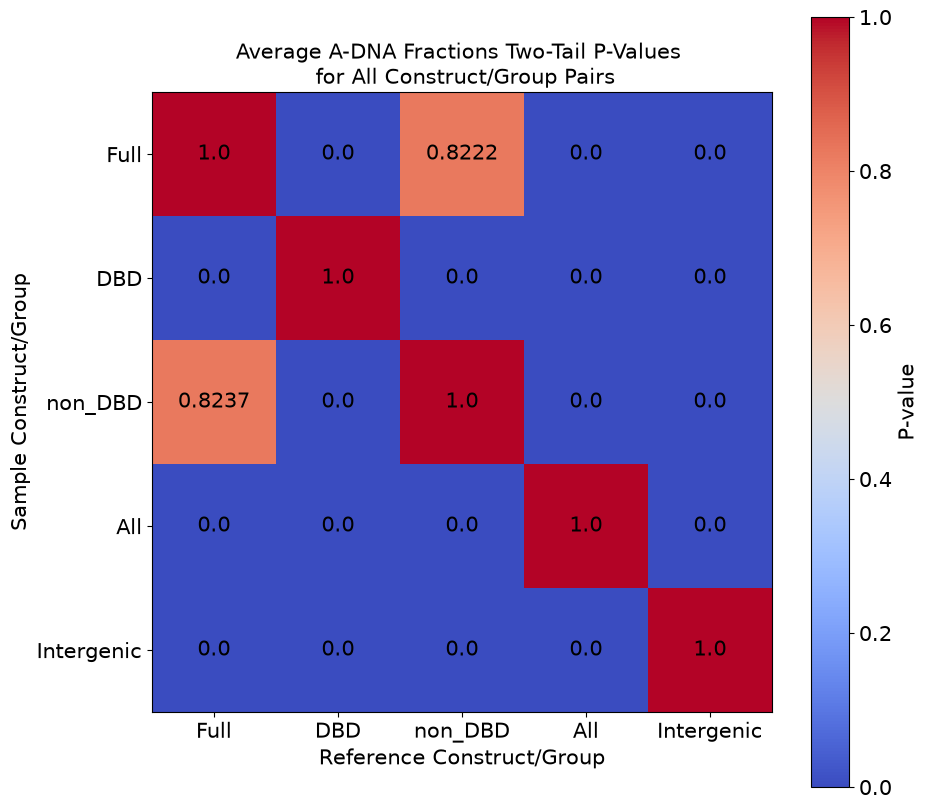

In [29]:
ts = time()
fs = 15
metric = 'A-DNA Fractions'
null_hypothesis = 'Different'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[0]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = constructs, size = fs)
ax.set_yticks(range(num_constructs), labels = constructs, size = fs)
ax.set_ylabel('Sample Construct/Group', fontsize = fs)
ax.set_xlabel('Reference Construct/Group', fontsize = fs)
ax.set_title('Average ' + metric + ' Two-Tail P-Values \n for All Construct/Group Pairs', fontsize = fs)
cbar = fig.colorbar(im, ax = ax, label = 'P-value')
cbar.ax.tick_params(labelsize = fs)
cbar.ax.set_ylabel('P-value', fontsize = fs)
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_avg_p_value_array[y,x], ha = 'center', va = 'center', fontsize = fs, color = 'k')
fig.savefig('A-DNA Dinucleotide Fraction Avg Two Tail P-values Heatmap.png')

It took 13.586994647979736 seconds to calculate all p-values


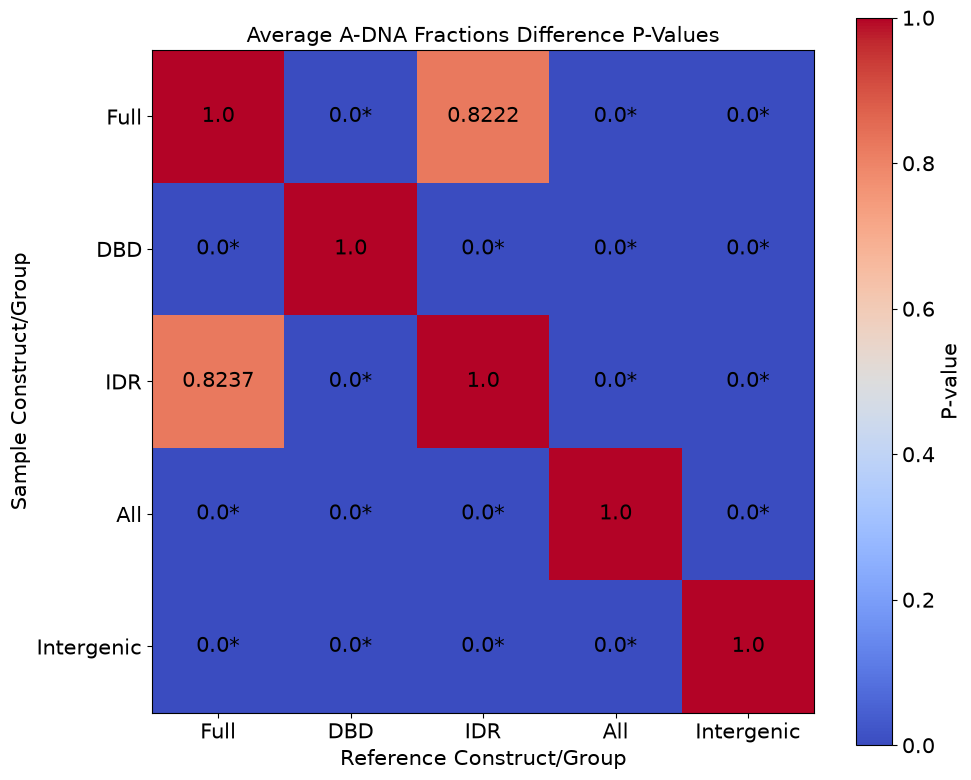

In [30]:
ts = time()
fs = 15
metric = 'A-DNA Fractions'
null_hypothesis = 'Different'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
construct_labels = ['Full', 'DBD', 'IDR', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[0]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = construct_labels, size = fs)
ax.set_yticks(range(num_constructs), labels = construct_labels, size = fs)
ax.set_ylabel('Sample Construct/Group', fontsize = fs)
ax.set_xlabel('Reference Construct/Group', fontsize = fs)
ax.set_title('Average ' + metric + ' Difference P-Values', fontsize = fs)

cbar = fig.colorbar(im, ax = ax, shrink = 0.75)
cbar.ax.tick_params(labelsize = fs)
cbar.ax.set_ylabel('P-value', fontsize = fs)
for y in range(num_constructs):
    for x in range(num_constructs):
        p_val = a_dna_density_avg_p_value_array[y,x]
        if p_val < 0.05:
            p_val_str = str(p_val) + '*'
        else:
            p_val_str = str(p_val)
        ax.text(x,y, p_val_str, ha = 'center', va = 'center', fontsize = fs)
fig.tight_layout()
fig.savefig('A-DNA Dinucleotide Fractions Avg Two Tail P-values Heatmap Presentation Style.png')

It took 13.59643030166626 seconds to calculate all p-values


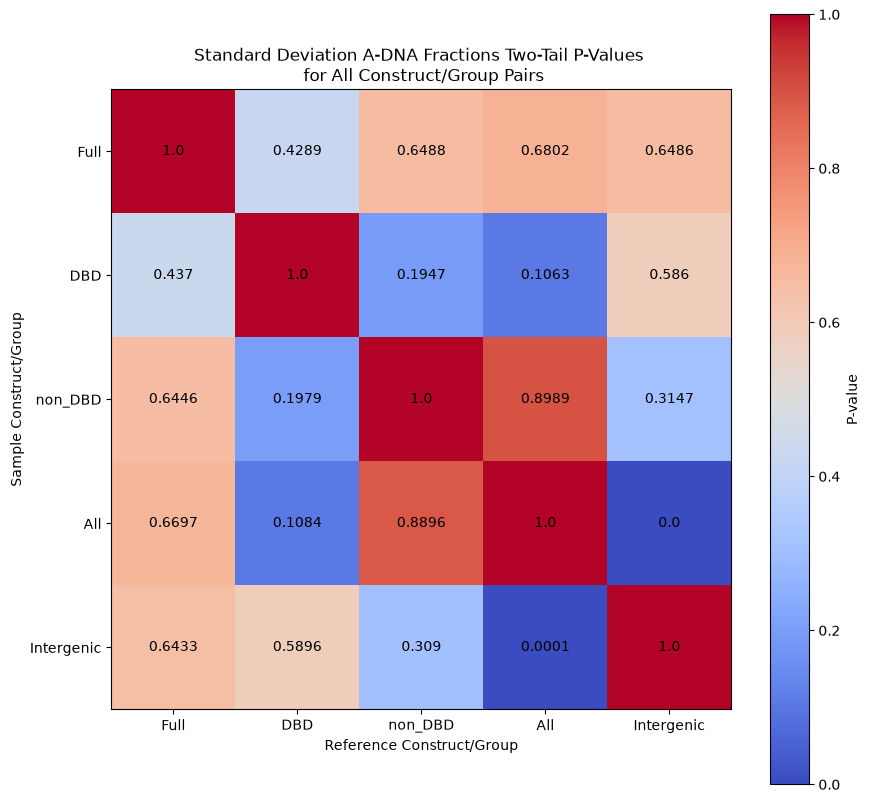

In [31]:
ts = time()
metric = 'A-DNA Fractions'
null_hypothesis = 'Different'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[1]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = constructs)
ax.set_yticks(range(num_constructs), labels = constructs)
ax.set_ylabel('Sample Construct/Group')
ax.set_xlabel('Reference Construct/Group')
ax.set_title('Standard Deviation ' + metric + ' Two-Tail P-Values \n for All Construct/Group Pairs')
cbar = fig.colorbar(im, ax = ax, label = 'P-value')
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_avg_p_value_array[y,x], ha = 'center', va = 'center')
fig.savefig('A-DNA Dinucleotide Fraction Std Two Tail P-values Heatmap.png')

It took 13.624374628067017 seconds to calculate all p-values


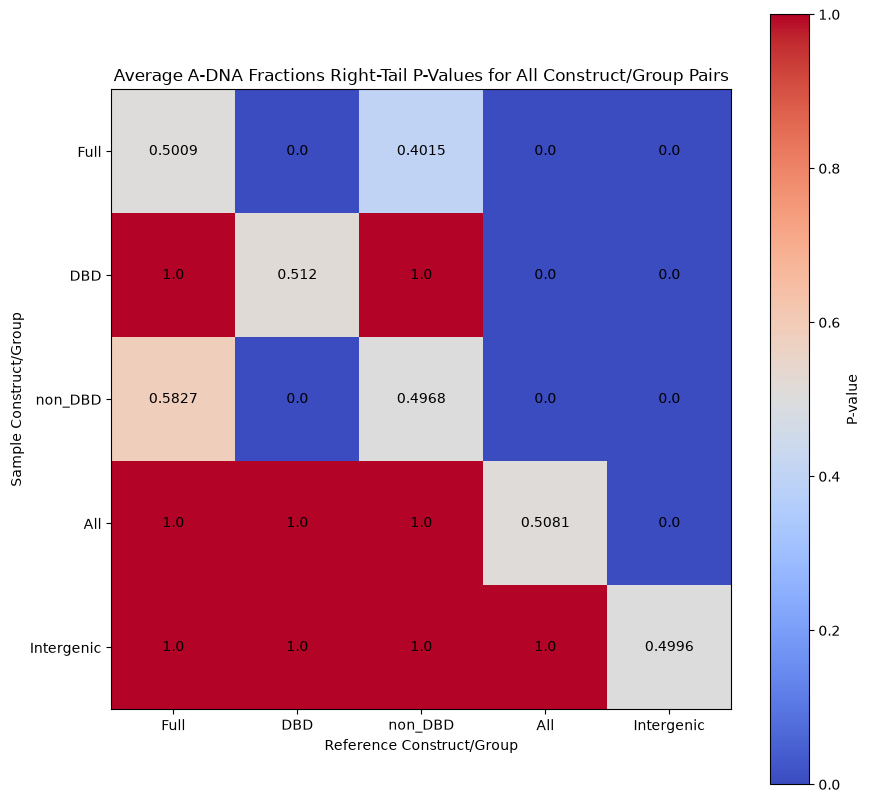

In [32]:
ts = time()
metric = 'A-DNA Fractions'
null_hypothesis = 'Larger'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[0]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = constructs)
ax.set_yticks(range(num_constructs), labels = constructs)
ax.set_ylabel('Sample Construct/Group')
ax.set_xlabel('Reference Construct/Group')
ax.set_title('Average ' + metric + ' Right-Tail P-Values for All Construct/Group Pairs')
cbar = fig.colorbar(im, ax = ax, label = 'P-value')
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_avg_p_value_array[y,x], ha = 'center', va = 'center')
fig.savefig('A-DNA Dinucleotide Fraction Avg Right Tail P-values Heatmap.png')

It took 13.56179165840149 seconds to calculate all p-values


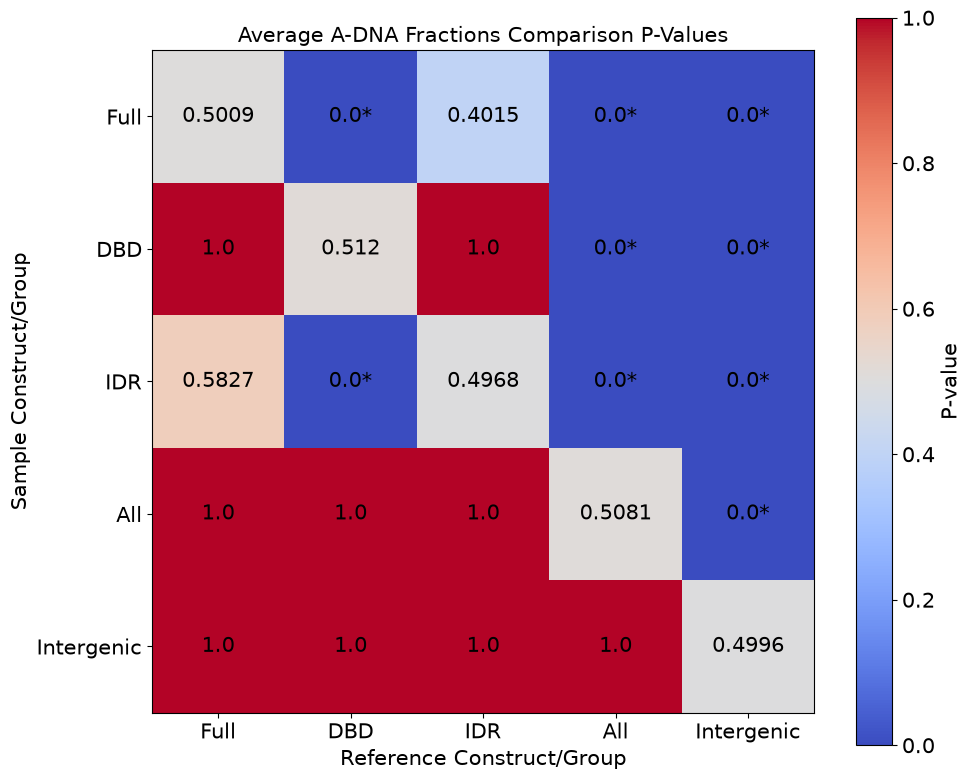

In [33]:
ts = time()
fs = 15
metric = 'A-DNA Fractions'
null_hypothesis = 'Larger'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
construct_labels = ['Full', 'DBD', 'IDR', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[0]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = construct_labels, size = fs)
ax.set_yticks(range(num_constructs), labels = construct_labels, size = fs)
ax.set_ylabel('Sample Construct/Group', fontsize = fs)
ax.set_xlabel('Reference Construct/Group', fontsize = fs)
ax.set_title('Average ' + metric + ' Comparison P-Values', fontsize = fs)

cbar = fig.colorbar(im, ax = ax, shrink = 0.75)
cbar.ax.tick_params(labelsize = fs)
cbar.ax.set_ylabel('P-value', fontsize = fs)
for y in range(num_constructs):
    for x in range(num_constructs):
        p_val = a_dna_density_avg_p_value_array[y,x]
        if p_val < 0.05:
            p_val_str = str(p_val) + '*'
        else:
            p_val_str = str(p_val)
        ax.text(x,y, p_val_str, ha = 'center', va = 'center', fontsize = fs)
fig.tight_layout()
fig.savefig('A-DNA Dinucleotide Fractions Avg Right Tail P-values Heatmap Presentation Style.png')

It took 13.572819709777832 seconds to calculate all p-values


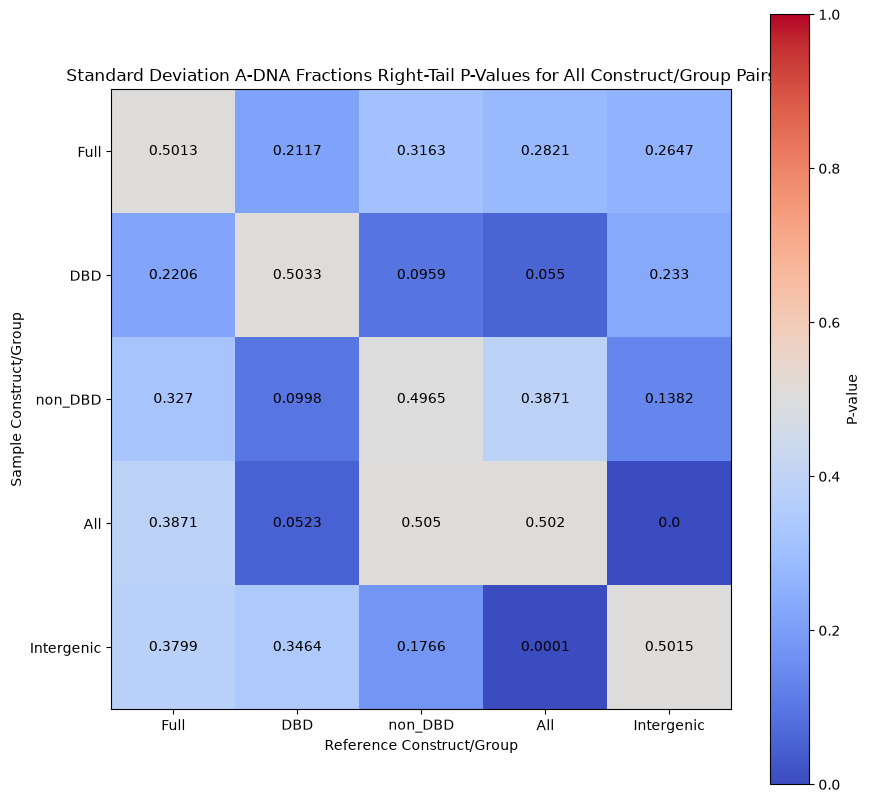

In [34]:
ts = time()
metric = 'A-DNA Fractions'
null_hypothesis = 'Larger'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_avg_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = avg_std_p_values_calc(coi, ref, metric, null_hypothesis)[1]
    a_dna_density_avg_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_avg_p_value_array, cmap = 'coolwarm', vmin = 0, vmax = 1)
ax.set_xticks(range(num_constructs), labels = constructs)
ax.set_yticks(range(num_constructs), labels = constructs)
ax.set_ylabel('Sample Construct/Group')
ax.set_xlabel('Reference Construct/Group')
ax.set_title('Standard Deviation ' + metric + ' Right-Tail P-Values for All Construct/Group Pairs')
cbar = fig.colorbar(im, ax = ax, label = 'P-value')
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_avg_p_value_array[y,x], ha = 'center', va = 'center')
fig.savefig('A-DNA Dinucleotide Fraction Std Right Tail P-values Heatmap.png')

P-values for the A-DNA Density avearge and standard deviations as well as A-DNA Fraction average and standard deviations indicate that all groups (Full, DBD, non_DBD, All, Intergenic_Regions) have statistically similar spreads when it comes to A-DNA dinucleotdies. However, the constructws (Full, DBD, non_DBD) have statistically larger averages compared to All and Intergenic_Regions. Additionally, the average A-DNA dinucleotide density and fraction between constructs is statistically the same. Thus, when only looking at CC, GG, CG, and GC content, this is larger in the constucts compared to off-target promoters and intergenic regions, but between constructs, it cannot account for why the Full and non_DBD differ from the DBD. 

# Box Plots and Violin Plots

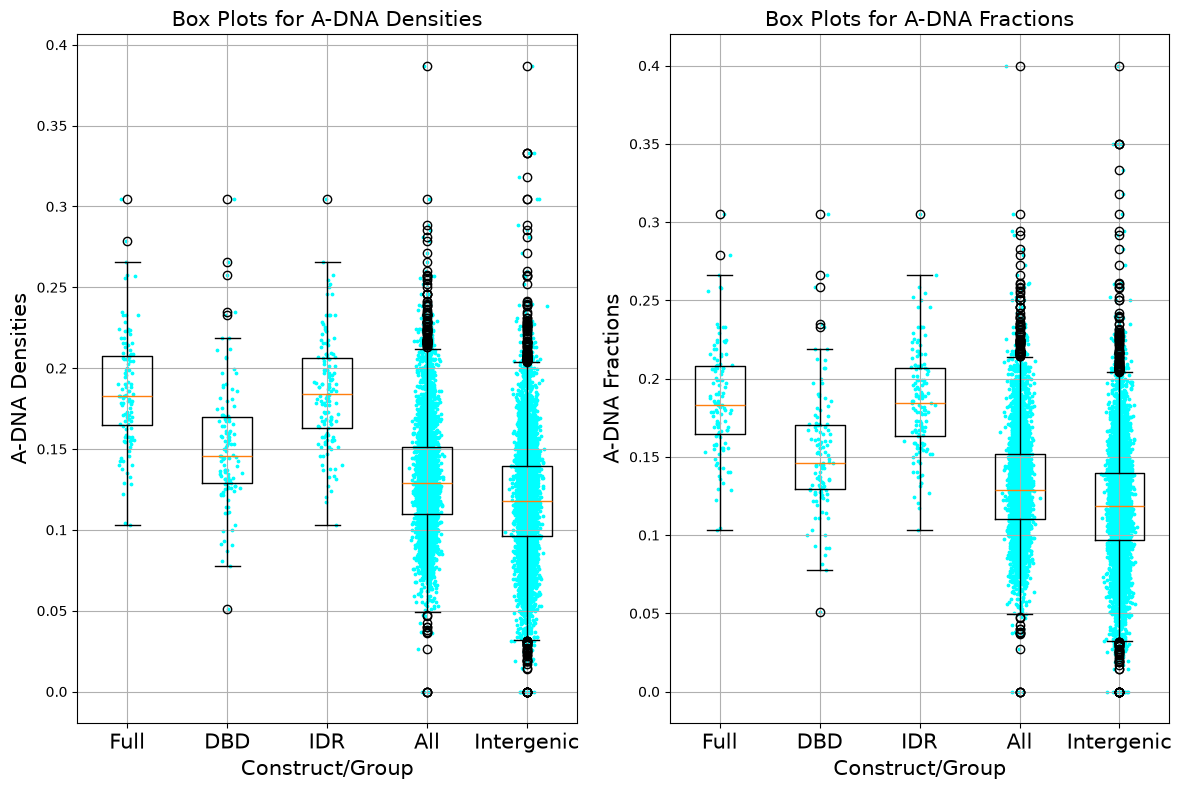

In [35]:
# create box plots of each group 
fig = plt.figure(figsize = (12,8))
ax = fig.subplots(1,2)
rng = np.random.default_rng(42)
constructs = ('Full','DBD', 'non_DBD', 'All', 'Intergenic')
construct_labels = ('Full','DBD', 'IDR', 'All', 'Intergenic')
num_constructs = len(constructs)
metrics = ('A-DNA Densities', 'A-DNA Fractions')
y_tick_pos = np.round(np.arange(0,0.45,0.05),2)
fs = 15

for col_idx, metric in enumerate(metrics):
    pos = 1
    if 'Densities' in metric:
        data_dict = eval('a_dna_density_dict')
        master_data = eval('master_density_data')
    else:
        data_dict = eval('a_dna_fraction_dict')
        master_data = eval('master_fraction_data')
    for construct in constructs:
        data = data_dict[construct]
        num_points = data.shape[0]
        scatter_pos = rng.normal(pos, 0.05, num_points)
        ax[col_idx].scatter(scatter_pos, data, s = 3, color = 'cyan')
        pos += 1
    ax[col_idx].boxplot(master_data)
    ax[col_idx].set_xticks([x+1 for x in range(num_constructs)], labels = construct_labels, size = fs)
    ax[col_idx].set_yticks(y_tick_pos, labels = y_tick_pos, size = fs-5)
    ax[col_idx].set_xlabel('Construct/Group', fontsize = fs)
    ax[col_idx].set_title('Box Plots for '+ metric, fontsize = fs)
    ax[col_idx].set_ylabel(metric, fontsize = fs)
    ax[col_idx].grid()
fig.tight_layout()
fig.savefig('A-DNA Dinucleotide Boxplots.png')

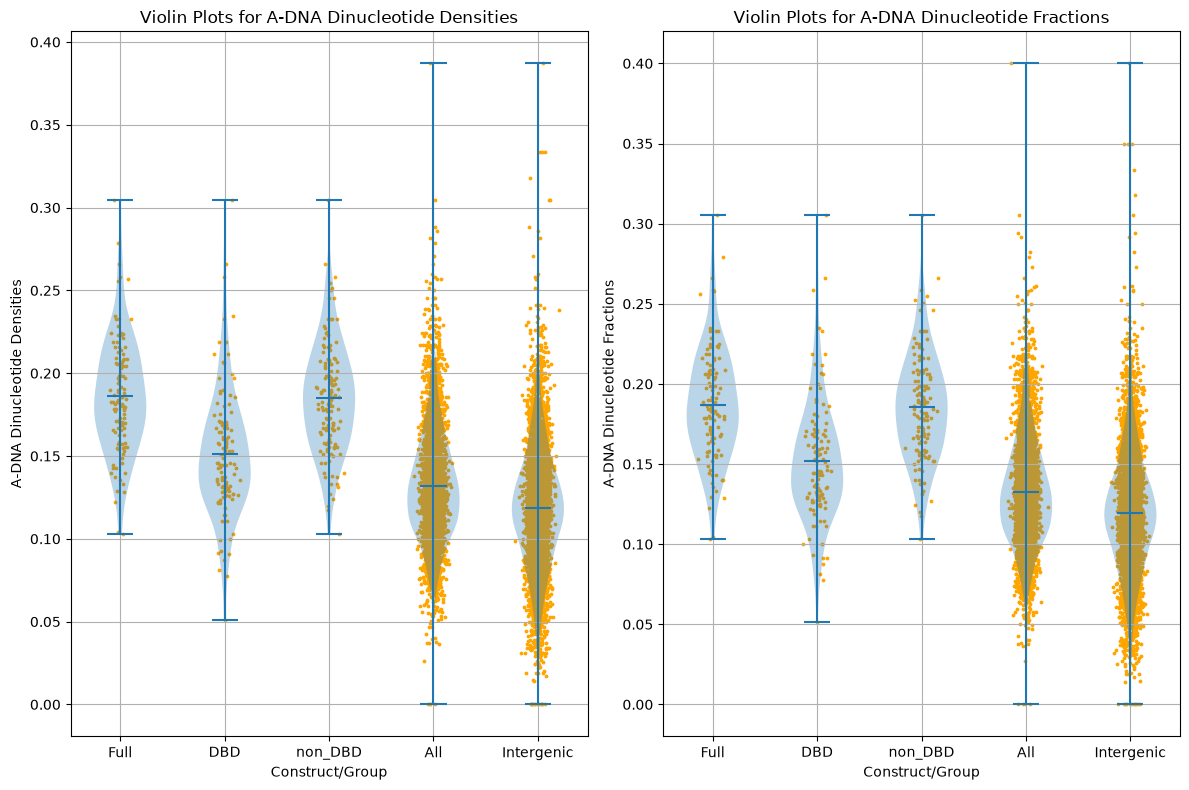

In [36]:
# create violin plots of each group 
fig = plt.figure(figsize = (12,8))
ax = fig.subplots(1,2)
rng = np.random.default_rng(42)
constructs = ('Full','DBD', 'non_DBD', 'All', 'Intergenic')
num_constructs = len(constructs)
metrics = ('A-DNA Dinucleotide Densities', 'A-DNA Dinucleotide Fractions')

for col_idx, metric in enumerate(metrics):
    pos = 1
    if 'Densities' in metric:
        data_dict = eval('a_dna_density_dict')
        master_data = eval('master_density_data')
    else:
        data_dict = eval('a_dna_fraction_dict')
        master_data = eval('master_fraction_data')
    for construct in constructs:
        data = data_dict[construct]
        num_points = data.shape[0]
        scatter_pos = rng.normal(pos, 0.05, num_points)
        ax[col_idx].scatter(scatter_pos, data, s = 3, color = 'orange')
        pos += 1
    ax[col_idx].violinplot(master_data, showmedians = False, showmeans = True)
    ax[col_idx].set_xticks([x+1 for x in range(num_constructs)], labels = constructs)
    ax[col_idx].set_xlabel('Construct/Group')
    ax[col_idx].set_ylabel(metric)
    ax[col_idx].set_title('Violin Plots for ' + metric)
    ax[col_idx].grid()
fig.tight_layout()
fig.savefig('A-DNA Dinucleotide Violin Plots.png')

Box Plots and Violin plots visually match the standard deviation and average p-values: the constructs have greater means (medians for box-plots) while having roughly the same spread. Additionally, the groups (All, Intergenic) have much larger range which matches what the KL values and log-odds suggests which is that while  the groups may have a few outliers at the higher fractions/densities compared to the constructs, the constructs generally have higher concentrations at higher densities/fractions. The real question is if this difference is enough to make a change in the specificity.

# P-Values for KL Distances

In [37]:
def KL_dist_calc_gkde(coi_1d_array, ref_1d_array, bins):
    '''
    Function that calculates the Kullback Leibler (KL) Distance between two constructs/groups. Their pdfs are first approximated using a 
    KDE approach with a Gaussian kernel then distance is calculated. 

    Parameters
    ----------
    coi_1d_array : 1D array
        Numpy 1D arry containing the data from the construct/group of interest AKA the data to use as the sample distribution.
    ref_1d_array : 1D array
        Numpy 1D array containing the data to use from the construct/group to be used for the reference distribution
    bins : 1D array
        Numpy 1D array containing the bins/grid to use for the KDE pdfs. The pdfs will be calculated for all of the values in bins.
    '''
    # concatenate the 1D arrays into a single array
    master_data_array = np.concat((coi_1d_array, ref_1d_array))
    # calculate a single bandwidth from all the data to ensure that the pdfs can be fairly compared
    bws = Scotts_rule_width(master_data_array)
    # calculate the coi(sample) and ref(reference) pdfs
    coi_pdfs = gkde(coi_1d_array, bins, bws) 
    ref_pdfs = gkde(ref_1d_array, bins, bws) 
    # calculate the KL distance at each point bins
    kl_distance_elements = coi_pdfs * np.log2(coi_pdfs / ref_pdfs)
    # because the pdfs are continous, integrate their KL distances rather than just sum them up.
    kl_distances = col_trap_int(kl_distance_elements, bins).squeeze()
    return kl_distances

def MC_ref_KL_dist_calc(coi_1d_array, ref_1d_array, bins, seed = 42, num_MC_samples = 10000, smoothing_factor = 1e-12):
    # grab the number of thresholds, number of coi promoters/sequences, and number of A-DNA subsequence lengths
    num_coi_seqs = coi_1d_array.shape[0]
    # grab the number of ref promoters/sequences
    num_ref_seqs = ref_1d_array.shape[0]
    # calculate the total number of promoters/sequences
    tot_num_seqs = int(num_coi_seqs + num_ref_seqs)
    # create an empty array to hold all the reference KL distances
    kl_distances_array = np.zeros((num_MC_samples))
    # create an array where each column is an index for all of the promoters/seqeucnes and there are num_MC_samples rows
    indices_array = np.tile(np.arange(tot_num_seqs, dtype = np.int16), (num_MC_samples,1))
    # create a numpy random generator to use for permutation
    rng = np.random.default_rng(seed)
    # permutate the columns of each row of the previous array to create MC samples
    mc_indices = rng.permuted(indices_array, axis = 1)
    # combine the coi and ref data into a single array to calculate a global bandwidth for MC samples
    master_1d_array = np.concat((coi_1d_array, ref_1d_array))
    bws = Scotts_rule_width(master_1d_array)
    # Calculate the KL distances for each MC sample
    # first create all of the MC samples by indexing the master_1d_array with mc_indices
    mc_samples_arrays = master_1d_array[mc_indices]
    # split each of the arrays into "coi" and "ref" groups
    mc_coi_arrays = mc_samples_arrays[:, :num_coi_seqs].T
    mc_ref_arrays = mc_samples_arrays[:, num_coi_seqs].T
    # estimate the pdfs for each "coi" and "ref" via KDE
    mc_coi_pdfs = gkde(mc_coi_arrays, bins, bws, smoothing_factor)
    mc_ref_pdfs = gkde(mc_ref_arrays, bins, bws, smoothing_factor)
    # calculate the KL distance between the pdfs at each point in the grid/bins
    kl_distance_elements = mc_coi_pdfs * np.log2(mc_coi_pdfs / mc_ref_pdfs)
    # integrate the KL distances per column to get the overall KL distance for each MC sample
    kl_distances_array = col_trap_int(kl_distance_elements, bins)
    return kl_distances_array.squeeze()

def p_value_calc_gkde(coi, ref, metric, bins, seed = 42, num_MC_samples = 10000, smoothing_factor = 1e-12):
    if 'Fractions' in metric:
        data_dict = eval('a_dna_fraction_dict')
    else:
        data_dict = eval('a_dna_density_dict')
    coi_1d_array = data_dict[coi]
    ref_1d_array = data_dict[ref]
    kl_distances_orig = KL_dist_calc_gkde(coi_1d_array, ref_1d_array, bins)
    kl_distances_ref = MC_ref_KL_dist_calc(coi_1d_array, ref_1d_array, bins, seed, num_MC_samples, smoothing_factor)
    p_values = np.sum(np.where(kl_distances_ref >= kl_distances_orig, 1, 0)) / num_MC_samples
    return p_values

def log_odds_significant_lengths_gkde(coi, ref, metric, bins, p_thresh = 0.05):
    '''
    Function that calculates the log-odds values between pdfs of the coi (sample) and ref(reference) constructs at subsequencelengths where 
    their KL distances are significant. A previously defined function is used to determine the significant lengths then the pdfs are 
    estimated using a KDE approach with a gaussian kernel.
    
    Parameters
    ----------
    coi : string ('Full', 'DBD', 'non_DBD', 'All', 'Intergenic Regions', 'Full_Flanks', 'DBD_Flanks', 'non_DBD_Flanks')
        Construct of interest / sample construct.
    ref : string ('Full', 'DBD', 'non_DBD', 'All', 'Intergenic Regions', 'Full_Flanks', 'DBD_Flanks', 'non_DBD_Flanks')
        Construct to use as a reference for construct of interest / sample construct.
    metric: string ('A_DNA_Subsequence_Densities', 'A_DNA_Subsequence_Fractions')
        Determines whether to grab the density array(s) or relative A-DNA content / subsequence fraction array(s)
    bins: array_like
        Sequence containing the bin edges to use for calculating the histograms of the data
    p_thresh : float (default : 0.05)
        p-value threshold for determining significant lengths. Any subsequence length with a p-value below the threshold is considered
        a signficant subsequenc length. The default value is 0.05 which is the one typically used in field.
    smoothing_factor : float (default : 1e-12)
        Value added to pdfs to prevent division by zero taking the logarithm of 0. Default is 1e-12.
    
    Returns
    -------
    log_odds: 3D numpy ndarray
        3D numpy holding the log-odds values across all thresholds and significant lengths. Each array is the log-odds for all significant
        lengths at a different threshold. Within each array, the columns are the log-odds values for a particular subsequence length.
    '''
    sig_lengths, sig_length_thresholds = significant_lengths_gkde(coi,ref,metric, p_thresh)
    sig_length_indices = sig_lengths - 2
    coi_array = array_retriever(coi, metric, 'All')[:, :, sig_length_indices]
    ref_array = array_retriever(ref, metric, 'All')[:, :, sig_length_indices]
    master_array = np.hstack((coi_array, ref_array))
    bws = Scotts_rule_width(master_array)
    coi_pdfs = gkde(coi_array, bins, bws) 
    ref_pdfs = gkde(ref_array, bins, bws) 
    log_odds = np.log2(coi_pdfs / ref_pdfs)
    return log_odds

In [38]:
coi_1d_array = a_dna_density_dict['Full'] 
ref_1d_array = a_dna_density_dict['Full']
bins = np.arange(0, 0.401, 0.001)
seed = 42 
num_MC_samples = 10000 
smoothing_factor = 1e-12

# grab the number of thresholds, number of coi promoters/sequences, and number of A-DNA subsequence lengths
num_coi_seqs = coi_1d_array.shape[0]
# grab the number of ref promoters/sequences
num_ref_seqs = ref_1d_array.shape[0]
# calculate the total number of promoters/sequences
tot_num_seqs = int(num_coi_seqs + num_ref_seqs)
# create an empty array to hold all the reference KL distances
kl_distances_array = np.zeros((num_MC_samples))
# create an array where each column is an index for all of the promoters/seqeucnes and there are num_MC_samples rows
indices_array = np.tile(np.arange(tot_num_seqs, dtype = np.int16), (num_MC_samples,1))
# create a numpy random generator to use for permutation
rng = np.random.default_rng(seed)
# permutate the columns of each row of the previous array to create MC samples
mc_indices = rng.permuted(indices_array, axis = 1)
# combine the coi and ref data into a single array to calculate a global bandwidth for MC samples
master_1d_array = np.concat((coi_1d_array, ref_1d_array))
bws = Scotts_rule_width(master_1d_array)
# Calculate the KL distances for each MC sample
# first create all of the MC samples by indexing the master_1d_array with mc_indices
mc_samples_arrays = master_1d_array[mc_indices]
# split each of the arrays into "coi" and "ref" groups
mc_coi_arrays = mc_samples_arrays[:, :num_coi_seqs].T
mc_ref_arrays = mc_samples_arrays[:, num_coi_seqs].T
# estimate the pdfs for each "coi" and "ref" via KDE
mc_coi_pdfs = gkde(mc_coi_arrays, bins, bws, smoothing_factor)
mc_ref_pdfs = gkde(mc_ref_arrays, bins, bws, smoothing_factor)
# calculate the KL distance between the pdfs at each point in the grid/bins
kl_distance_elements = mc_coi_pdfs * np.log2(mc_coi_pdfs / mc_ref_pdfs)
# integrate the KL distances per column to get the overall KL distance for each MC sample
kl_distances_array = col_trap_int(kl_distance_elements, bins)

In [39]:
x = kl_distances_array
x

array([[[0.01954186, 0.01945078, 0.01936955, ..., 0.02220506,
         0.00306238, 0.03165452]]], shape=(1, 1, 10000))

In [40]:
coi = 'Full' 
ref  = 'Full'
metric = 'A-DNA Densities'
step = 0.001
bins = np.arange(0,1+step, step)
seed = 42 
num_MC_samples = 10000
smoothing_factor = 1e-12
if 'Fractions' in metric:
    data_dict = eval('a_dna_fraction_dict')
else:
    data_dict = eval('a_dna_density_dict')
coi_1d_array = data_dict[coi]
ref_1d_array = data_dict[ref]
kl_distances_orig = KL_dist_calc_gkde(coi_1d_array, ref_1d_array, bins)
kl_distances_ref = MC_ref_KL_dist_calc(coi_1d_array, ref_1d_array, bins, seed, num_MC_samples, smoothing_factor)
p_values = np.sum(np.where(kl_distances_ref >= kl_distances_orig, 1, 0)) / num_MC_samples

In [41]:
kl_distances_orig

array(0.)

In [42]:
kl_distances_ref

array([0.01954186, 0.01945078, 0.01936955, ..., 0.02220506, 0.00306238,
       0.03165452], shape=(10000,))

It took 24.838485956192017 seconds to calculate all p-values


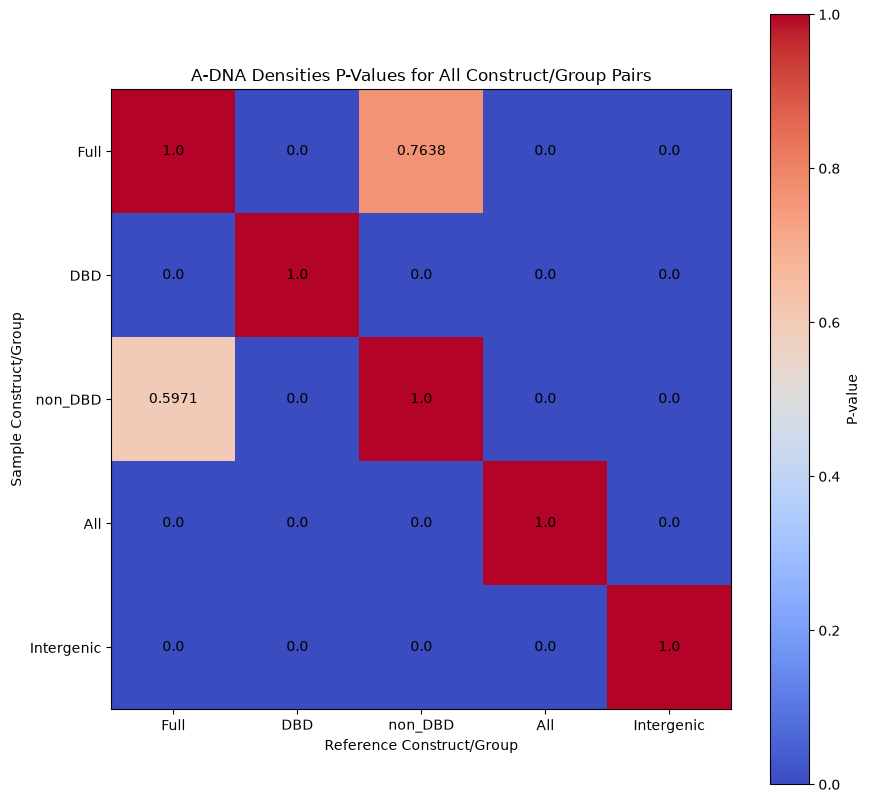

In [43]:
# with the ability to calculate p-vales for each construct/group pair, can create a heatmap to see which pairs have values less than 0.05
# start with A-DNA Density

ts = time()
metric = 'A-DNA Densities'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(constructs, repeat = 2))
# define the bin edeges
step = 0.001
grid = np.arange(0, 1+step, step)
# get the total number of constructs/group
num_constructs = len(constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_density_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the A-DNA Density p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = p_value_calc_gkde(coi, ref, metric, grid)
    a_dna_density_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_density_p_value_array, cmap = 'coolwarm')
ax.set_xticks(range(num_constructs), labels = constructs)
ax.set_yticks(range(num_constructs), labels = constructs)
ax.set_ylabel('Sample Construct/Group')
ax.set_xlabel('Reference Construct/Group')
ax.set_title(metric + ' P-Values for All Construct/Group Pairs')
cbar = fig.colorbar(im, ax = ax, label = 'P-value')
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_density_p_value_array[y,x], ha = 'center', va = 'center')

It took 19.35074758529663 seconds to calculate all p-values


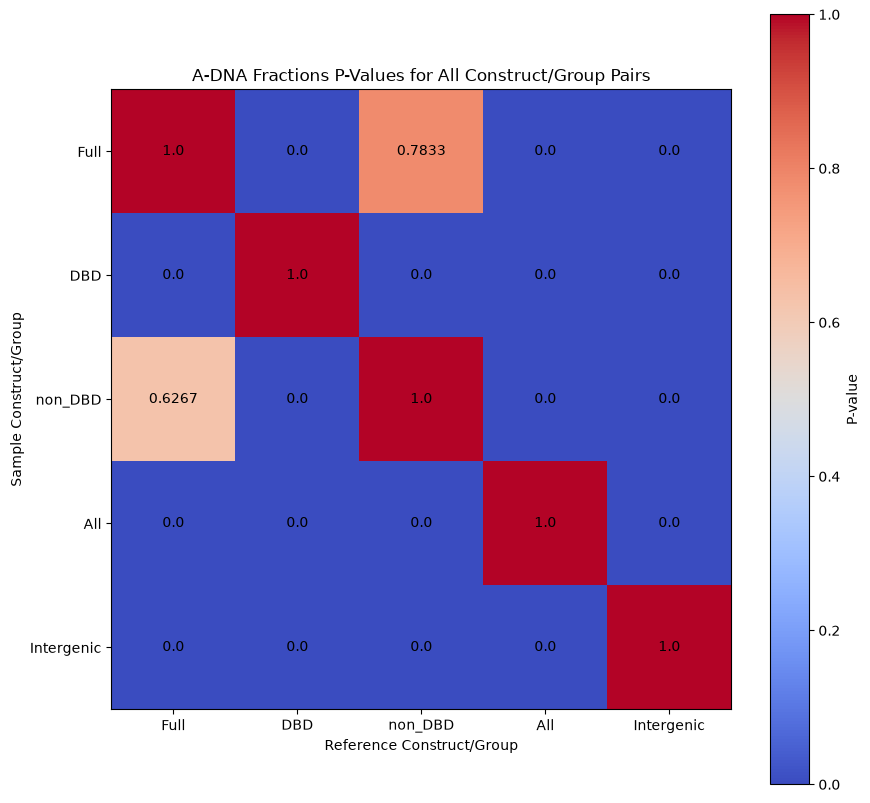

In [44]:
# now do the same as above but for Relative A-DNA Content

ts = time()
metric = 'A-DNA Fractions'
# for now, will not inlcude nonspecific sequences since they include all of the coding regions which is less reasonable than exlcuding
# all coding regions
#all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS']
all_constructs = ['Full', 'DBD', 'non_DBD', 'All', 'Intergenic']
# get all possible construct/group combos
pairs_to_compare = list(product(all_constructs, repeat = 2))
# define the bin edeges
step = 0.01
grid = np.arange(0, 1+step, step)
# get the total number of constructs/group
num_constructs = len(all_constructs)
# use total number of constructs/groups to create an empty array that holds all the p-values
a_dna_fraction_p_value_array = np.zeros([num_constructs, num_constructs])
# calculate the Relative A-DNA Content p-values for all possible contruct/group combos
for pair in pairs_to_compare:
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    p_value = p_value_calc_gkde(coi, ref, metric, grid)
    a_dna_fraction_p_value_array[coi_index, ref_index] = p_value
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of Relative A-DNA Content p-values
plt.close()
fig = plt.figure(figsize = [10,10])
ax = fig.add_subplot(1,1,1)
im = ax.imshow(a_dna_fraction_p_value_array, cmap = 'coolwarm')
ax.set_xticks(range(num_constructs), labels = all_constructs)
ax.set_yticks(range(num_constructs), labels = all_constructs)
ax.set_ylabel('Sample Construct/Group')
ax.set_xlabel('Reference Construct/Group')
ax.set_title(metric + ' P-Values for All Construct/Group Pairs')
cbar = fig.colorbar(im, ax = ax, label = 'P-value')
for y in range(num_constructs):
    for x in range(num_constructs):
        ax.text(x,y, a_dna_fraction_p_value_array[y,x], ha = 'center', va = 'center')

From these P-value heatmaps, we can say the following about Msn2 promoters and their A-DNA dinucleotide content. Both relative A-DNA dinucleotide content and A-DNA dinucleotide Density measure similiar metrics, but from different perspectives. Interestingly, they do say the same thing about A-DNA dinucleotides. If we take p-values < 0.05 to be significant. We can see that the A-DNA Density and Relative A-DNA content distributions are different when comparing any of the 3 constructs (Full, DBD, and IDR/non_DBD) to either all promoters or all intergenic regions. I should note that the 0 p-value is due to not sampling enough reference KL distances. I will bump that up to 50,000 maybe since 100,000 takes significantly longer to calculate. Moreover, we use all intergenic regions rather all intergenic regions + coding regions since the former is likely more like reality; most of the yeast genome (about 80% per Mirny et al's paper) is inaccessible to due being in chromatin. Thus, while there is definitley some coding regions available for off-target Msn2 binding, there's likely not a lot. Thus, since we do not have the ability to predict which coding regions would be accessible, not including any coding regions is a convenient and more relevant simplification. When comparing between the 3 constructs, the distrubtions are statistically the same. This would seem to imply that the A-DNA content between them is about the same. While many of these promoters are shared, we could likely do this same procedure with the promoters unique to each construct and see what happens. We should likely recover the same results as Jonas et al. (2024) and it would be a nice if we get the same results as it would serve as a check that our methods measure the same thing. If we want to draw conclusions about who has more/less A-DNA we need heatmaps showing the log-odds for each construct/group pair over all the bins. That is the next objective.

# Log-Odds

In [45]:
# now we need to calculate the log_odds between each construct/group pair for each bin
def log_odds_calc(coi, ref, metric, bins, smoothing_factor = 1e-12):
    '''
    Function to calculate the Kullback-Leibler (KL) distance between a construct of interest (coi)'s distribution taken as the sample
    distribution and anoter construct's distribution chosen as the reference distirbution (ref).

    Parameters
    ----------
    coi : 'Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS'
        Construct/group of interest whose PDF will be used as a the sample distribution for the KL distance.
    ref: 'Full', 'DBD', 'non_DBD', 'All', 'Intergenic', 'Full_NS', 'DBD_NS', 'non_DBD_NS'
        Construct/group to  use for the reference distribution in the KL distance calculation.
    metric : 'A-DNA Density', 'Relative A-DNA Content'
        Determine whether to pick the pdfs for A-DNA Density or Relative A-DNA Content
    bins: array_like
        Defines the edges of each bin to use for the histogram and pdf.
    smoothing factor : float (default = 1e.12)
        Decimal added to PDF-values to ensure that there is no division by 0 or no log2(0). Default value is 1e-12.

    Returns
    -------
    log_odds_vals : numpy ndarray
        1D array containing the log odds values between the coi and ref for each bin.
    '''
    # grab either A-DNA density or Relative A-DNA content values depending on the value of 'metric'.
    if 'Densities' in metric:
        coi_vals = a_dna_density_dict[coi] 
        ref_vals = a_dna_density_dict[ref] 
    else:
        coi_vals = a_dna_fraction_dict[coi] 
        ref_vals = a_dna_fraction_dict[ref]
    # calculate pdfs for coi and ref and add smoothing factor to them
    coi_pdf = gkde(coi_vals, bins, density_bw, smoothing_factor)
    ref_pdf = gkde(ref_vals, bins, fraction_bw, smoothing_factor)
    # calculate logs
    log_odds_vals = np.log2(coi_pdf/ref_pdf) 
    return log_odds_vals.ravel()


It took 0.0022296905517578125 seconds to calculate all p-values




In [46]:
# visualize log-odds between two constructs/groups at each bin using a heatmap
# start with A-DNA Density

ts = time()
metric = 'A-DNA Density'
# unlike KL distance which is asymmetric, log-odds are symmetric so we don't need every possible construct/group combo
# we will explicitly define the ones we want to see
select_pairs_to_compare = [('Full', 'DBD'), ('Full', 'non_DBD'), ('non_DBD', 'DBD'),
                           ('Full', 'All'), ('DBD', 'All'), ('non_DBD', 'All'),
                           ('Full', 'Intergenic'), ('DBD', 'Intergenic'), ('non_DBD', 'Intergenic')]
# reverse the order of the combos so that the heatmaps will match later
select_pairs_to_compare = select_pairs_to_compare[::-1]
num_combos = len(select_pairs_to_compare)
# define the bin edeges
step = 0.001
grid = np.arange(0,1+step, step)
num_grid_points = grid.shape[0]
bins = np.round(np.arange(0, 0.41, 0.01),2)
num_bins = len(bins)-1
# initialize an array to hold the log odds values for each combo
# each row is the log-odds for a combo and each column is the log-odds value for a particular bin
a_dna_density_log_odds_array = np.zeros([num_combos, num_grid_points])
# calculate the A-DNA Density log odds values for the contruct/group combos
for idx,pair in enumerate(select_pairs_to_compare):
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    log_odds_array = log_odds_calc(coi, ref, metric, grid)
    a_dna_density_log_odds_array[idx,:] = log_odds_array
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density log odds values
plt.close()
fs = 40
column_label_pos = np.arange(0.5,9,1)
ax_grid = np.arange(0,1+ 2*step, step)
xticks_pos = np.round(np.arange(0,1.05,0.05),2)
y_labels = [f'{i[0]} / {i[1]}' for i in select_pairs_to_compare]
fig = plt.figure(figsize = [150,10])
ax = fig.add_subplot(1,1,1)
im = ax.pcolormesh(ax_grid, range(num_combos+1),a_dna_density_log_odds_array, cmap = 'gist_rainbow', edgecolor = 'k')
ax.set_yticks(column_label_pos, labels = y_labels, fontsize = fs)
ax.set_xticks(xticks_pos, labels = xticks_pos, fontsize = fs)
ax.set_ylabel('Combos (Sample/ Ref)', fontsize = fs)
ax.set_xlabel(metric + ' Bins', fontsize = fs)
ax.set_title(metric + ' Log Odds for All Construct/Group Pairs', fontsize = fs)
cbar = fig.colorbar(im, ax = ax)
cbar.set_label('Log Odds Value', fontsize = fs)
cbar.set_ticks(np.arange(-40,50,10), labels = np.arange(-40,50,10), fontsize = fs)
'''
text_x_pos = np.arange(0.005, 0.4005, 0.01)
for ncol in range(len(column_label_pos)):
    for nrow in range(num_bins):
        ax.text(text_x_pos[nrow], column_label_pos[ncol], np.round(a_dna_density_log_odds_array[ncol,nrow],1),ha ='center',  
                va = 'center', fontsize = fs)
'''
fig.tight_layout()
# when using ax.text, it goes ax.text(row_val, col_val, text, kwargs)

It took 0.0024139881134033203 seconds to calculate all p-values




In [47]:
# now do relative A-DNA content

ts = time()
metric = 'A-DNA Fractions'
# unlike KL distance which is asymmetric, log-odds are symmetric so we don't need every possible construct/group combo
# we will explicitly define the ones we want to see
select_pairs_to_compare = [('Full', 'DBD'), ('Full', 'non_DBD'), ('non_DBD', 'DBD'),
                           ('Full', 'All'), ('DBD', 'All'), ('non_DBD', 'All'),
                           ('Full', 'Intergenic'), ('DBD', 'Intergenic'), ('non_DBD', 'Intergenic')]
# reverse the order of the combos so that the heatmaps will match later
select_pairs_to_compare = select_pairs_to_compare[::-1]
num_combos = len(select_pairs_to_compare)
# define the bin edeges
step = 0.001
grid = np.arange(0,1+step, step)
num_grid_points = grid.shape[0]
bins = np.round(np.arange(0, 0.41, 0.01),2)
num_bins = len(bins)-1
# initialize an array to hold the log odds values for each combo
# each row is the log-odds for a combo and each column is the log-odds value for a particular bin
a_dna_density_log_odds_array = np.zeros([num_combos, num_grid_points])
# calculate the A-DNA Density log odds values for the contruct/group combos
for idx,pair in enumerate(select_pairs_to_compare):
    coi, ref = pair
    coi_index = all_constructs.index(coi)
    ref_index = all_constructs.index(ref)
    log_odds_array = log_odds_calc(coi, ref, metric, grid)
    a_dna_density_log_odds_array[idx,:] = log_odds_array
tf = time()
print(f'It took {tf-ts} seconds to calculate all p-values')
# create heatmap from array of A-DNA Density log odds values
plt.close()
fs = 40
column_label_pos = np.arange(0.5,9,1)
ax_grid = np.arange(0,1+ 2*step, step)
xticks_pos = np.round(np.arange(0,1.05,0.05),2)
y_labels = [f'{i[0]} / {i[1]}' for i in select_pairs_to_compare]
fig = plt.figure(figsize = [150,10])
ax = fig.add_subplot(1,1,1)
im = ax.pcolormesh(ax_grid, range(num_combos+1),a_dna_density_log_odds_array, cmap = 'gist_rainbow', edgecolor = 'k')
ax.set_yticks(column_label_pos, labels = y_labels, fontsize = fs)
ax.set_xticks(xticks_pos, labels = xticks_pos, fontsize = fs)
ax.set_ylabel('Combos (Sample/ Ref)', fontsize = fs)
ax.set_xlabel(metric + ' Bins', fontsize = fs)
ax.set_title(metric + ' Log Odds for All Construct/Group Pairs', fontsize = fs)
cbar = fig.colorbar(im, ax = ax)
cbar.set_label('Log Odds Value', fontsize = fs)
cbar.set_ticks(np.arange(-40,50,10), labels = np.arange(-40,50,10), fontsize = fs)
'''
text_x_pos = np.arange(0.005, 0.4005, 0.01)
for ncol in range(len(column_label_pos)):
    for nrow in range(num_bins):
        ax.text(text_x_pos[nrow], column_label_pos[ncol], np.round(a_dna_density_log_odds_array[ncol,nrow],1),ha ='center',  
                va = 'center', fontsize = fs)
'''
fig.tight_layout()
# when using ax.text, it goes ax.text(row_val, col_val, text, kwargs)

Now that we have the log odds heat maps, we can draw more insightful interpretations about the KL distance p-values from earlier. Like with said KL distance p-values, both A-DNA density and Relative A-DNA Content say basically the same thing. This is not surprising as since we are looking at dinucleotdies, the number of dinucleotides in a sequences is very close to the number of bp (only differ by 1), so we expect them to say the same things. When it comes to comparing either of the three constructs (Full, DBD, non_DBD/IDR) to either all promoters or all intergenic regions, we can see that those significant KL distances are due to the constructs lacking many of the lower A-DNA densities/relative A-DNA content as well as a number of the densities between 0.2 and 0.3. However, in the aforementioned range, there are also densities/content that the contructs have that the intergenic and all promoters lack. Additionally, the negative log odds for densities/content > 0.3 seems to be due to outliers not present in the constructs. This statement is based on the A-DNA density and Relative A-DNA content pdfs from earlier. When it comes to comparing between constructs, the Full has a few higher density bins that are much more poulated than the DBD and non_DBD. Interestingly, the non_DBD and DBD promoters have very similar distributions with only one bin being different between them. Overall, I don't really think I can conclude much about the A-DNA dincleotide content between the constructs and other groups. All three constructs have very similar A-DNA content and while the constructs do not have as many lower A-DNA content members, at higher content values, they are quite similar. When it comes to content between 0.2 and 0.3, there are more density/content values where All promoters and all intergenic regions win out, though there are a few where the constructs win out. Ultimately, what we can say is that constructs have a much smaller range of A-DNA content/density values and if we exclude the outliers in the all promoter groups and all intergenic regions, it is likely that the average A-DNA content of the constructs will be greater.

# Correlation Between ChEC-Seq Signal and A-DNA Content

In [48]:
constructs = ['Full', 'DBD', 'non_DBD']
promoter_scores_dict = {}
for construct in constructs:
    promoter_scores = pd.read_csv(f'Msn2_{construct}_60sec_Target_Promoters_Info.csv').iloc[:,5].values.flatten().tolist()
    promoter_scores_dict[construct] = promoter_scores

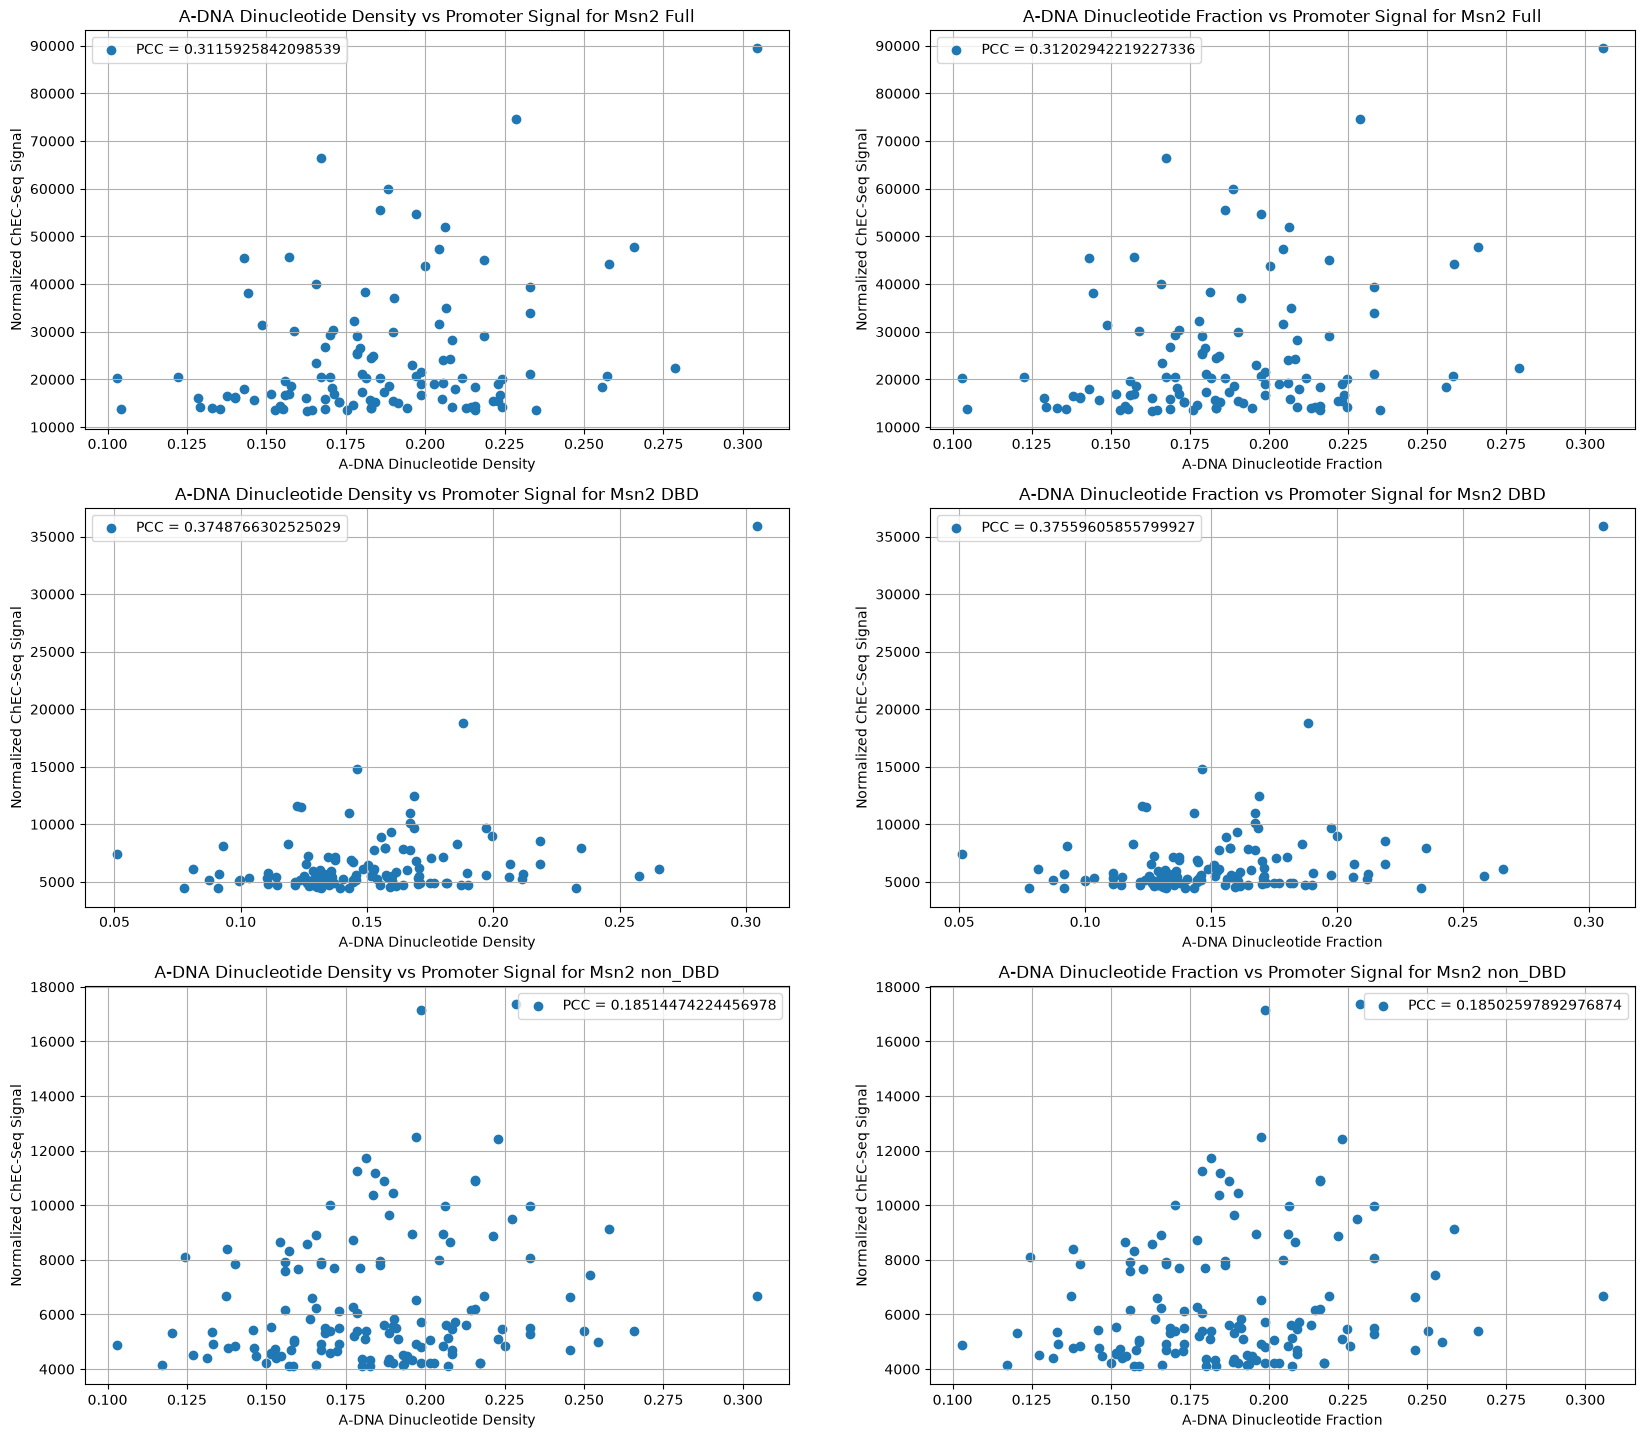

In [49]:
constructs = ['Full', 'DBD', 'non_DBD']
num_construct = len(constructs)
fig = plt.figure(figsize = (20,30))
graph_idx = 0
for construct in constructs:
    graph_idx += 1
    densities = a_dna_density_dict[construct]
    fractions = a_dna_fraction_dict[construct]
    promoter_scores = promoter_scores_dict[construct]
    max_score = np.round(max(promoter_scores))
    density_correlation = np.corrcoef(densities, promoter_scores)[0,1]
    fraction_correlation = np.corrcoef(fractions, promoter_scores)[0,1]
    
    ax = fig.add_subplot(num_constructs,2,graph_idx)
    ax.scatter(densities, promoter_scores, label = f'PCC = {density_correlation}')
    ax.set_xlabel('A-DNA Dinucleotide Density')
    ax.set_ylabel('Normalized ChEC-Seq Signal')
    ax.set_title(f'A-DNA Dinucleotide Density vs Promoter Signal for Msn2 {construct}')
    ax.grid()
    ax.legend()

    graph_idx += 1
    ax = fig.add_subplot(num_constructs,2,graph_idx)
    ax.scatter(fractions, promoter_scores, label = f'PCC = {fraction_correlation}')
    ax.set_xlabel('A-DNA Dinucleotide Fraction')
    ax.set_ylabel('Normalized ChEC-Seq Signal')
    ax.set_title(f'A-DNA Dinucleotide Fraction vs Promoter Signal for Msn2 {construct}')
    ax.grid()
    ax.legend()